# Week 09: The Optimization Perspective of Federated Learning

Week 9 studies three ways to handle this problem:

- **FedProx**: adds a penalty for moving too far from the server model. It reduces drift, but does not always improve accuracy. Think of it as a brake.
- **SCAFFOLD**: uses control variates to correct local update directions. It can remove drift bias in our quadratic example, but requires extra communication and persistent client state.
- **Consensus optimization**: replaces the server with communication between neighbours. The graph determines how quickly clients agree: a ring mixes slowly; complete, uniform averaging reaches agreement in one step.

The codebase also moves to Flower, keeping model parameters, optimizer state, batch statistics, and random state separate.

## Learning Objectives

By the end of this session, you will be able to:
- Explain why different client objectives can bias `FedAvg`.
- Measure drift and visualize label skew using Dirichlet partitions.
- Run the `Equinox` model through `Flower` clients.
- Verify that `FedProx` with μ=0 matches `FedAvg`.
- Compare the benefits and costs of `FedProx` and `SCAFFOLD`.

In [1]:
import time
import functools

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import equinox as eqx
import optax

import flwr

key = jax.random.key(0)
rng = np.random.default_rng(0)

print("jax     ", jax.__version__)
print("equinox ", eqx.__version__)
print("optax   ", optax.__version__)
print("flwr    ", flwr.__version__)
print("devices :", len(jax.devices()), "x", jax.devices()[0].device_kind)

jax      0.10.2
equinox  0.13.8
optax    0.2.8
flwr     1.32.1
devices : 1 x cpu


>What this setup can show. This CPU-only laptop cannot tell us how fast training runs on a phone or GPU. It can still demonstrate drift, bias, rounds to a target, communication bytes, and graph mixing. These measurements describe the chosen experiment; wall-clock timings depend on hardware.

>We use synthetic CIFAR-shaped data and 6 Flower clients for a few rounds. The full lab uses CIFAR-10 via Grain and 100 clients on the server. Results may change at that scale. When an effect is small here, we report it as small and explain why—as we will in Section 5.


---

## 1. The mismatch: what you asked for vs what FedAvg gives you

Each client minimizes its local loss:

$$F_k(\theta) = \frac{1}{n_k}\sum_{i \in \mathcal{D}_k} \ell_i(\theta).$$

But we want to minimize the loss over all examples:

$$F(\theta) = \sum_k p_k F_k(\theta), \qquad p_k = \frac{n_k}{\sum_j n_j}.$$

With non-IID data, clients may prefer different models. Taking several local steps before
averaging can therefore move FedAvg away from the global optimum.

A quadratic makes this precise. Suppose

$$F_k(w) = \frac{1}{2}(w - w_k)^\top H_k (w - w_k),$$

where $w_k$ is the client's preferred model and $H_k$ describes its curvature. After $\tau$
local gradient steps with learning rate $\eta$, define

$$M_k = I - (I - \eta H_k)^\tau.$$

Compare the equations for the global optimum and a FedAvg fixed point:

$$
\underbrace{\sum_k p_k H_k(\theta^\star - w_k) = 0}_{\text{global optimum}},
\qquad
\underbrace{\sum_k p_k M_k(w^\infty - w_k) = 0}_{\text{FedAvg fixed point}}.
$$

The difference is the weighting: $H_k$ becomes $M_k$.

- **One local step:** $M_k = \eta H_k$, so the equations agree exactly. With full
  participation and exact gradients, FedAvg is gradient descent on $F$.
- **Multiple local steps:** clients with different curvatures can be reweighted differently.
  FedAvg may converge to a biased solution, even without gradient noise.

We will verify the fixed-point formula numerically and measure how the bias changes with
$\tau$. Multiple steps can introduce bias; they do not guarantee it in every problem.


In [2]:
# Three clients, three strongly anisotropic quadratics pointing in different directions.
# This is "non-IID" reduced to its mathematical essence: DIFFERENT F_k.
K_Q = 3

def rot(t):
    return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

ANGLES = [0.0, np.pi / 3, 2 * np.pi / 3]
D_CURV = np.diag([4.0, 0.25])                       # condition number 16 within each client
Hs = np.array([rot(a) @ D_CURV @ rot(a).T for a in ANGLES])
wks = np.array([[2.0, 1.0], [-1.5, 2.0], [0.5, -2.5]])   # each client's OWN optimum
p_q = np.ones(K_Q) / K_Q                            # equal client sizes, so p_k = 1/K

# The global optimum: sum_k p_k H_k (w - w_k) = 0
H_bar = np.einsum("k,kij->ij", p_q, Hs)
b_bar = np.einsum("k,kij,kj->i", p_q, Hs, wks)
w_star = np.linalg.solve(H_bar, b_bar)

def F_global(w):
    return sum(p_q[k] * 0.5 * (w - wks[k]) @ Hs[k] @ (w - wks[k]) for k in range(K_Q))

def grad_k(k, w):
    return Hs[k] @ (w - wks[k])

print("client optima w_k (each client's OWN minimizer):")
for k in range(K_Q):
    print(f"   client {k}: {wks[k]}   curvature eigenvalues {np.linalg.eigvalsh(Hs[k])}")
print(f"\nglobal optimum theta* = {w_star}")
print(f"F(theta*) = {F_global(w_star):.4f}")
print(f"\nnote theta* is NOT the average of the w_k = {wks.mean(axis=0)}")
print("   -- because the clients disagree about CURVATURE as well as location, and the")
print("      global optimum is a curvature-weighted compromise, not a positional one.")
print(f"      distance between the two: {np.linalg.norm(w_star - wks.mean(axis=0)):.4f}")

client optima w_k (each client's OWN minimizer):
   client 0: [2. 1.]   curvature eigenvalues [0.25 4.  ]
   client 1: [-1.5  2. ]   curvature eigenvalues [0.25 4.  ]
   client 2: [ 0.5 -2.5]   curvature eigenvalues [0.25 4.  ]

global optimum theta* = [ 2.21483754 -0.7104071 ]
F(theta*) = 1.7394

note theta* is NOT the average of the w_k = [0.33333333 0.16666667]
   -- because the clients disagree about CURVATURE as well as location, and the
      global optimum is a curvature-weighted compromise, not a positional one.
      distance between the two: 2.0759


>Observe: all three clients have the same curvatures, but their steep directions differ. As a result, the global optimum $\theta^\star$ lies outside the triangle of client optima. Minimizing the average loss is different from averaging the best local models.

>| Model | Global loss |
>|---|---:|
>| Global optimum $\theta^\star$ | 1.74 |
>| Average local optimum w̄ | 6.32 |

>These are FedAvg’s two extremes:

>- τ=1: each update preserves curvature information, so FedAvg can converge to $\theta^\star$.
>- τ→∞: with a stable learning rate, every client reaches its own optimum wₖ. The server averages those positions and obtains w̄, whose loss is about 3.6× higher.

>Why does curvature disappear? The fraction of distance covered along a direction with curvature λ is

>$$m(\lambda)=1-(1-\eta\lambda)^\tau.$$

>With η=0.1, the steep-to-flat weight ratio falls from 16 at one step to 4.4 at ten steps and 1.08 at a hundred steps. Given enough steps, both directions reach the local optimum, so their different speeds stop mattering.

>SCAFFOLD addresses this by correcting local update directions.

>Finally, client 1 has higher loss at the global optimum than at w̄ ($3.09$ versus $1.68$). The best shared model need not be best for every client—one motivation for personalization in Week 11.


In [3]:
def fedavg_quadratic(rounds, tau, eta, mu=0.0, w0=None):
    # FedAvg on the quadratics, with the K clients vectorized onto a leading axis (the numpy
    # equivalent of the vmap we use on the real model). mu > 0 adds FedProx's proximal
    # term -- and that ONE term is the entire difference between the two algorithms.
    w = np.zeros(2) if w0 is None else w0.copy()
    traj = [w.copy()]
    for r in range(rounds):
        Y = np.tile(w, (K_Q, 1))                                  # broadcast theta^(r)
        for t in range(tau):
            G = np.einsum("kij,kj->ki", Hs, Y - wks)              # each client's own grad
            Y = Y - eta * (G + mu * (Y - w))                      # <- the ONE extra term
        w = np.einsum("k,kj->j", p_q, Y)                          # THE aggregation
        traj.append(w.copy())
    return np.array(traj)


def fedavg_fixed_point(tau, eta):
    # The closed form derived above: solve sum_k p_k M_k (w - w_k) = 0 with
    # M_k = I - (I - eta H_k)^tau.  At tau=1 this reduces to sum_k p_k H_k (w - w_k) = 0.
    M = np.array([np.eye(2) - np.linalg.matrix_power(np.eye(2) - eta * Hs[k], tau)
                  for k in range(K_Q)])
    A = np.einsum("k,kij->ij", p_q, M)
    b = np.einsum("k,kij,kj->i", p_q, M, wks)
    return np.linalg.solve(A, b)

In [4]:
ETA_Q = 0.1
taus_q = [1, 2, 5, 10, 20, 50]

print(f"eta = {ETA_Q}, 600 rounds (converged), K = {K_Q} clients, full participation")
print(f"{'tau':>5}  {'FedAvg fixed point':>28}  {'closed-form prediction':>28}  "
      f"{'|emp - pred|':>13}  {'BIAS |w - theta*|':>18}")
print("-" * 102)
bias_q = []
for tau in taus_q:
    emp = fedavg_quadratic(600, tau, ETA_Q)[-1]
    pred = fedavg_fixed_point(tau, ETA_Q)
    bias = np.linalg.norm(pred - w_star)
    bias_q.append(bias)
    print(f"{tau:>5}  {str(np.round(emp, 6)):>28}  {str(np.round(pred, 6)):>28}  "
          f"{np.linalg.norm(emp - pred):>13.2e}  {bias:>18.4f}")

print(f"\nThe closed form predicts where FedAvg lands to ~1e-15. This is not a fit and not")
print("an approximation -- it is the fixed-point equation solved on paper.")
print(f"\ntau=1  bias = {bias_q[0]:.2e}  <- EXACT. FedAvg with one local step minimizes F.")
print(f"tau=50 bias = {bias_q[-1]:.4f}  <- FedAvg converged, to the wrong point.")

eta = 0.1, 600 rounds (converged), K = 3 clients, full participation
  tau            FedAvg fixed point        closed-form prediction   |emp - pred|   BIAS |w - theta*|
------------------------------------------------------------------------------------------------------
    1         [ 2.214838 -0.710407]         [ 2.214838 -0.710407]       1.90e-15              0.0000
    2         [ 2.160252 -0.684962]         [ 2.160252 -0.684962]       1.35e-15              0.0602
    5         [ 1.978648 -0.600306]         [ 1.978648 -0.600306]       1.34e-15              0.2606
   10         [ 1.682296 -0.46216 ]         [ 1.682296 -0.46216 ]       1.12e-15              0.5876
   20         [ 1.253034 -0.262057]         [ 1.253034 -0.262057]       1.40e-15              1.0612


   50           [0.683333 0.003512]           [0.683333 0.003512]       1.00e-15              1.6897

The closed form predicts where FedAvg lands to ~1e-15. This is not a fit and not
an approximation -- it is the fixed-point equation solved on paper.

tau=1  bias = 9.93e-16  <- EXACT. FedAvg with one local step minimizes F.
tau=50 bias = 1.6897  <- FedAvg converged, to the wrong point.


> **Observe:**
>
> - **The formula matches the experiment:** errors are around $10^{-15}$, confirming the
>   predicted fixed point and convergence within 600 rounds.
> - **One local step gives zero bias:** FedAvg reaches the global optimum $\theta^\star$.
> - **More local steps increase bias in this example:**
>   $0 \to 0.06 \to 0.26 \to 0.59 \to 1.06 \to 1.69$.
> - **The result approaches the average local optimum $\bar w$:** at $\tau = 50$, it is only
>   $0.39$ away (compared with $2.08$ between $\theta^\star$ and $\bar w$). Longer local training gradually removes curvature information from the
>   averaging.
>
> The key lesson: FedAvg can converge smoothly to a biased solution. A stable training curve
> alone does not prove that it reached the global optimum.


bias at tau=1 : 9.93e-16   (exactly zero, up to float noise)
bias at tau=60: 1.7867
for scale, the client optima are spread over ~2.67

The green tau=1 trajectory walks to the star. The red tau=20 trajectory walks
somewhere else, just as confidently and just as monotonically.


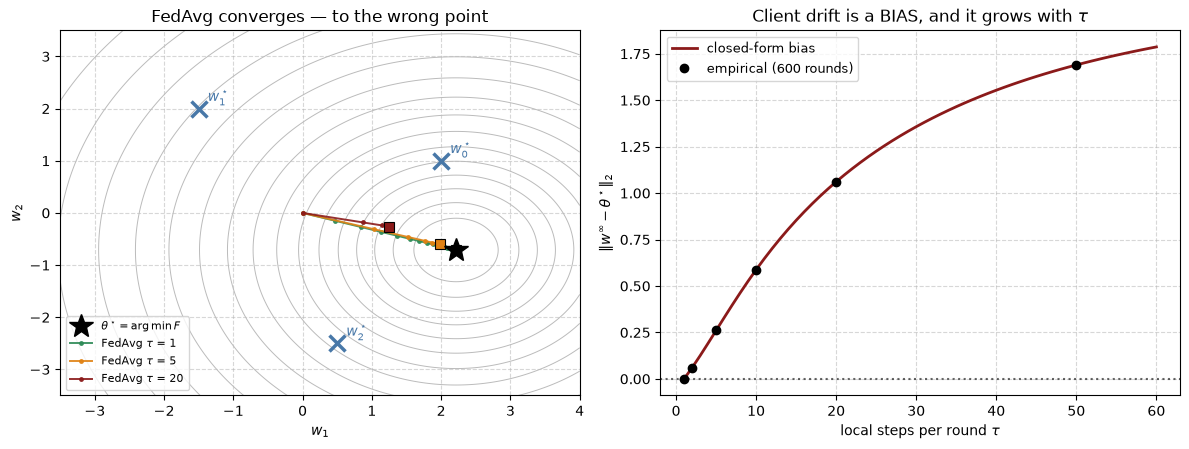

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

# ---- left: the geometry ----
gx, gy = np.meshgrid(np.linspace(-3.5, 4.0, 220), np.linspace(-3.5, 3.5, 220))
Z = np.zeros_like(gx)
for i in range(gx.shape[0]):
    for j in range(gx.shape[1]):
        Z[i, j] = F_global(np.array([gx[i, j], gy[i, j]]))
ax[0].contour(gx, gy, Z, levels=np.geomspace(Z.min() + 1e-3, Z.max(), 18),
              colors="#bbbbbb", linewidths=0.7)

for k in range(K_Q):
    ax[0].plot(*wks[k], "x", color="#4878a8", ms=11, mew=2.5)
    ax[0].annotate(f"$w_{k}^\\star$", wks[k] + 0.13, fontsize=10, color="#4878a8")
ax[0].plot(*w_star, "*", color="k", ms=18, label=r"$\theta^\star = \arg\min F$", zorder=5)

for tau, c in [(1, "#2e8b57"), (5, "#e08214"), (20, "#8b1a1a")]:
    tr = fedavg_quadratic(60, tau, ETA_Q)
    ax[0].plot(tr[:, 0], tr[:, 1], "o-", color=c, ms=2.5, lw=1.4, alpha=0.9,
               label=f"FedAvg $\\tau$ = {tau}")
    ax[0].plot(*tr[-1], "s", color=c, ms=7, mec="k", mew=0.8)
ax[0].set_xlabel("$w_1$"); ax[0].set_ylabel("$w_2$")
ax[0].set_title("FedAvg converges — to the wrong point")
ax[0].legend(fontsize=8, loc="lower left")
ax[0].grid(True, ls="--", alpha=0.5)

# ---- right: bias vs tau ----
taus_fine = np.arange(1, 61)
bias_fine = [np.linalg.norm(fedavg_fixed_point(int(t), ETA_Q) - w_star) for t in taus_fine]
ax[1].plot(taus_fine, bias_fine, "-", color="#8b1a1a", lw=2, label="closed-form bias")
ax[1].plot(taus_q, bias_q, "o", color="k", ms=6, label="empirical (600 rounds)")
ax[1].axhline(0, color="k", ls=":", alpha=0.6)
ax[1].set_xlabel(r"local steps per round $\tau$")
ax[1].set_ylabel(r"$\|w^\infty - \theta^\star\|_2$")
ax[1].set_title(r"Client drift is a BIAS, and it grows with $\tau$")
ax[1].legend(fontsize=9)
ax[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()

print(f"bias at tau=1 : {bias_fine[0]:.2e}   (exactly zero, up to float noise)")
print(f"bias at tau=60: {bias_fine[-1]:.4f}")
print(f"for scale, the client optima are spread over ~{np.max(np.linalg.norm(wks - wks.mean(0), axis=1)):.2f}")
print("\nThe green tau=1 trajectory walks to the star. The red tau=20 trajectory walks")
print("somewhere else, just as confidently and just as monotonically.")

> **Observe:** all three trajectories converge smoothly, but $\tau = 5$ and $\tau = 20$ reach
> biased endpoints. In this example, the bias grows toward $2.08$, the distance between the
> global optimum and the average client optimum.
>
> Three lessons guide the rest of the notebook:
>
> 1. **Bias can exist without noise.** These runs use exact gradients and full
>    participation. More rounds cannot remove the bias. A smaller learning rate reduces it,
>    but slows progress per round.
> 2. **Multiple local steps change the weighting.** Steep directions approach each client's
>    optimum first; flatter directions catch up later. As $\tau$ grows, averaging
>    increasingly treats all directions equally, losing the curvature weighting needed for
>    the global optimum.
> 3. **Local computation creates a trade-off.** One local step avoids this bias but requires
>    frequent communication. We want the communication savings of many local steps while
>    controlling their bias.
>
> Next, we compare **FedProx**, which limits movement from the broadcast model, and
> **SCAFFOLD**, which corrects local update directions.

---

## 2. Manufacturing non-IID data: the Dirichlet partition

Clients have different objectives because they own different data. A Dirichlet partition
lets us control how unevenly labels are distributed.

For each class $c$, we draw proportions across $K$ clients:

$$\mathbf{p}_c \sim \text{Dir}(\alpha \mathbf{1}_K),$$

then split that class's examples using those proportions.

| $\alpha$ | Typical partition |
|---|---|
| Large, e.g. $10$ | Nearly uniform: clients have similar label distributions |
| $1$ | Noticeable label skew |
| Small, e.g. $0.3$ | Strong label skew |
| $\to 0$ | Each class concentrates on one client |

Small $\alpha$ does not mean one class per client: a client may receive several classes or
almost no data.

This class-wise procedure changes both label distributions **and** client sizes, so both can
affect our results. If we redraw partitions to enforce a minimum client size, we must report
that restriction. Dirichlet partitioning is a useful controlled model; it does not guarantee
realistic heterogeneity.

For this offline notebook, we generate synthetic CIFAR-shaped images:

$$x = T_c + \sigma\varepsilon,$$

where $T_c$ is a smooth class-specific template and $\varepsilon$ is random noise. The
templates create a learnable relationship between images and labels, allowing us to study
how label skew affects training.

In [6]:
# ---------------- The Stage 1-3 codebase, carried forward ----------------
IMG, N_CLASSES = 32, 10                    # CIFAR-10 shaped, on purpose
K = 6                                      # clients (the real Lab 7 runs 100 on the GPU node)
B_LOCAL, TAU, LR = 16, 16, 0.4

def make_model(key, c=8):
    # Same architecture as Week 7's SmallCNN -- conv/BN/relu x2, global average pool, linear
    # head -- but assembled from equinox LIBRARY classes rather than a bespoke eqx.Module
    # subclass. That is not cosmetic; Section 4 explains why it is load-bearing.
    k1, k2, k3 = jax.random.split(key, 3)
    return eqx.nn.Sequential([
        eqx.nn.Conv2d(3, c, 3, stride=2, padding=1, use_bias=False, key=k1),
        eqx.nn.BatchNorm(c, axis_name="batch", mode="batch", momentum=0.9),
        eqx.nn.Lambda(jax.nn.relu),
        eqx.nn.Conv2d(c, c, 3, stride=2, padding=1, use_bias=False, key=k2),
        eqx.nn.BatchNorm(c, axis_name="batch", mode="batch", momentum=0.9),
        eqx.nn.Lambda(jax.nn.relu),
        eqx.nn.Lambda(lambda h: jnp.mean(h, axis=(1, 2))),      # global average pool
        eqx.nn.Linear(c, N_CLASSES, key=k3),
    ])


# ---- The FOUR states, kept explicitly apart since Week 3. Stage 4 is where that pays. ----
#   1. params    -- the arrays we differentiate and average           -> ON THE WIRE
#   2. bn_state  -- batch statistics (not differentiated)             -> ON THE WIRE (but see below)
#   3. opt_state -- optimizer state                                   -> LOCAL, rebuilt per round
#   4. PRNG key  -- threaded explicitly, never global                 -> LOCAL
model0, bn0 = eqx.nn.make_with_state(make_model)(jax.random.key(0))
params0, static0 = eqx.partition(model0, eqx.is_inexact_array)

optimizer = optax.sgd(LR)
opt0 = optimizer.init(params0)

N_PARAMS = sum(p.size for p in jax.tree.leaves(params0))
N_BN = sum(l.size for l in jax.tree.leaves(bn0))

def batched_forward(model, state, x):
    return eqx.filter_vmap(lambda m, s, xi: m(xi, state=s), in_axes=(None, None, 0),
                           out_axes=(0, None), axis_name="batch")(model, state, x)

def loss_fn(model, state, x, y):
    logits, state = batched_forward(model, state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state


print(f"params    : {N_PARAMS:,} values -> {N_PARAMS * 4:,} bytes on the wire at float32")
print(f"bn_state  : {N_BN} values (running mean/var + counter) -- a SEPARATE state")
print(f"opt_state : SGD, {sum(l.size for l in jax.tree.leaves(opt0))} values -- stays local")
print(f"\nTiny on purpose: this lab measures ROUNDS, DRIFT and BIAS, not FLOPs.")

params    : 914 values -> 3,656 bytes on the wire at float32
bn_state  : 34 values (running mean/var + counter) -- a SEPARATE state
opt_state : SGD, 0 values -- stays local

Tiny on purpose: this lab measures ROUNDS, DRIFT and BIAS, not FLOPs.


> **Observe:** nothing new is learned in this cell — it carries the Stage 1–3 codebase
> forward so that Stage 4 changes only *where* the code runs, not *what* it computes.
>
> - **Same model, different assembly.** The architecture is Week 7's SmallCNN, but it is
>   built from Equinox **library classes** inside `eqx.nn.Sequential` instead of a
>   notebook-defined `eqx.Module` subclass. A notebook-defined Module loses its PyTree
>   registration when cloudpickled into a Ray worker — `jax.tree.leaves(params)` silently
>   returns `[]` and the failure surfaces much later. Section 4 shows why this choice is
>   what lets the code run in real Flower processes.
> - **The four states decide what goes on the wire.** `eqx.partition` splits the trainable
>   arrays (`params0`) from the static structure (`static0`); only `params` (and, for now,
>   `bn_state`) are sent to the server. The optimizer state and PRNG key stay local.
> - **Tiny on purpose.** $914$ parameters ($3.6$ KB at float32): this lab measures rounds,
>   drift and bias, not FLOPs.
> - **`opt_state` has $0$ values.** Plain SGD has no state, so "rebuilt per round" is a
>   no-op here. With momentum or Adam, whether to reset or carry the optimizer state across
>   rounds becomes a real design choice.
> - **`bn_state` is shipped but inert.** With `mode="batch"`, BatchNorm normalizes with the
>   current batch's statistics even at evaluation, so the running statistics we send do not
>   affect the test loss. Section 4 discusses this caveat; Week 11 (FedBN) builds the
>   harness that can actually score it.
> - $K = 6$ clients keeps the notebook fast; the real Lab 7 runs 100 clients on the GPU node.


In [7]:
# ---------------- Synthetic CIFAR-shaped data with REAL class structure ----------------
# No network in the harness. The real Lab 7 points at CIFAR-10 via Grain on the GPU node.
# The point of the smooth template is that the task is genuinely learnable and genuinely
# class-structured -- otherwise label skew would mean nothing and this lab would be empty.
NOISE = 2.0

def make_templates(key):
    lo = jax.random.normal(key, (N_CLASSES, 3, 8, 8))
    return jax.image.resize(lo, (N_CLASSES, 3, IMG, IMG), method="linear")

TEMPLATES = make_templates(jax.random.key(7))

def make_data(n, key, noise=NOISE):
    kl, kn = jax.random.split(key)
    labels = jax.random.randint(kl, (n,), 0, N_CLASSES)
    return TEMPLATES[labels] + jax.random.normal(kn, (n, 3, IMG, IMG)) * noise, labels

X_all, Y_all = make_data(6000, jax.random.key(1))
X_te, Y_te = make_data(1000, jax.random.key(2))
Xh, Yh = np.asarray(X_all), np.asarray(Y_all)


@eqx.filter_jit
def evaluate(params, bn, x, y):
    logits, _ = batched_forward(eqx.combine(params, static0), bn, x)
    l = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return l, jnp.mean(jnp.argmax(logits, -1) == y)


print(f"train {X_all.shape}   test {X_te.shape}   {N_CLASSES} classes, noise sigma = {NOISE}")
l0, a0 = evaluate(params0, bn0, X_te, Y_te)
print(f"at init : test loss {float(l0):.4f}  acc {float(a0):.3f}  (chance = {1 / N_CLASSES:.3f})")

# The CENTRALIZED CEILING, at a matched example budget. Every federated run below does
# R rounds x tau local steps x B examples on each of K clients; pooling that gives
# R*tau steps of batch K*B. Same gradient work, one machine, all the data. This is what
# federated learning is trying to approximate; we do not expect it to beat it.
CENTRAL_STEPS, CENTRAL_BS = 40 * TAU, K * B_LOCAL
_opt = optax.sgd(LR)
@eqx.filter_jit
def _step(p, b, o, x, y):
    (l, b2), g = jax.value_and_grad(
        lambda pp, ss: loss_fn(eqx.combine(pp, static0), ss, x, y), has_aux=True)(p, b)
    u, o2 = _opt.update(g, o, p)
    return eqx.apply_updates(p, u), b2, o2
_p, _b, _o = params0, bn0, _opt.init(params0)
_r = np.random.default_rng(0)
for _ in range(CENTRAL_STEPS):
    _i = _r.choice(len(X_all), CENTRAL_BS, replace=False)
    _p, _b, _o = _step(_p, _b, _o, X_all[_i], Y_all[_i])
_l, _a = evaluate(_p, _b, X_te, Y_te)
print(f"CENTRALIZED reference: {CENTRAL_STEPS} steps of pooled SGD at batch {CENTRAL_BS} "
      f"({CENTRAL_STEPS * CENTRAL_BS:,} examples)")
print(f"   -> test loss {float(_l):.4f}   acc {float(_a):.3f}")
print("   ^ the federated runs in Section 8 use the same gradient budget. The gap to this")
print("     reference is what splitting the data across clients costs.")

train (6000, 3, 32, 32)   test (1000, 3, 32, 32)   10 classes, noise sigma = 2.0
at init : test loss 2.3564  acc 0.111  (chance = 0.100)


CENTRALIZED reference: 640 steps of pooled SGD at batch 96 (61,440 examples)
   -> test loss 0.1123   acc 0.980
   ^ the federated runs in Section 8 use the same gradient budget. The gap to this
     reference is what splitting the data across clients costs.


> **Observe:** the synthetic task is learnable. The untrained model is at chance (accuracy
> about $0.11$ against $0.10$), and centralized SGD on the pooled data reaches about $98\%$
> test accuracy. This centralized run is the reference for Section 8: the federated runs
> there process the same number of training examples, so any gap comes from how the data is
> split, not from a smaller training budget.


In [8]:
def dirichlet_partition(Y, n_clients, alpha, seed=0):
    # Yurochkin et al. (2019) / Wang et al. (2020), class-major form. For each class, draw
    # p_c ~ Dir(alpha * 1_K) and split that class's examples across clients in those
    # proportions. No min_size guard: a client can end up with very few examples, or none.
    r = np.random.default_rng(seed)
    Yn = np.asarray(Y)
    shards = [[] for _ in range(n_clients)]
    for c in range(N_CLASSES):
        idx = np.where(Yn == c)[0]
        r.shuffle(idx)
        prop = r.dirichlet(np.repeat(alpha, n_clients))          # <- the ONE line
        cuts = (np.cumsum(prop) * len(idx)).astype(int)[:-1]
        for k, part in enumerate(np.split(idx, cuts)):
            shards[k].extend(part.tolist())
    # dtype matters: at tiny alpha a client can end up with ZERO examples, and an empty
    # np.array defaults to float64 -- which then fails as an index. Say int64 and mean it.
    return [np.array(sorted(s), dtype=np.int64) for s in shards]


def label_matrix(shards):
    # (K, N_CLASSES) counts -- the object the heatmap draws and the skew metric scores.
    return np.stack([np.bincount(Yh[s], minlength=N_CLASSES) for s in shards])


def skew_tv(shards):
    # Mean total-variation distance between each client's label distribution and the global
    # one. 0 = perfectly IID; -> 1 - 1/N_CLASSES as clients collapse onto single classes.
    # EMPTY clients are skipped: a client with no data has no label distribution, and
    # scoring it as "all zeros" would credit it with TV = 0.5 and drag the mean DOWN --
    # making the metric non-monotone in alpha exactly where the skew is most extreme.
    M = label_matrix(shards).astype(float)
    q = M.sum(0) / M.sum()
    tv = [0.5 * np.abs(M[k] / M[k].sum() - q).sum()
          for k in range(len(shards)) if M[k].sum() > 0]
    return float(np.mean(tv)) if tv else float("nan")


ALPHAS = [100.0, 10.0, 1.0, 0.3, 0.1]
PARTS = {a: dirichlet_partition(Y_all, K, a, seed=3) for a in ALPHAS}

print(f"Dirichlet partitions of {len(X_all):,} examples over K = {K} clients")
print(f"{'alpha':>7}  {'label skew (TV)':>15}  {'n_k min':>8}  {'n_k max':>8}  "
      f"{'size imbalance':>15}  {'classes/client':>15}")
print("-" * 82)
for a in ALPHAS:
    sh = PARTS[a]
    M = label_matrix(sh)
    sizes = M.sum(1)
    # how many classes hold >=5% of a client's data?
    ncls = np.mean([(M[k] / max(sizes[k], 1) >= 0.05).sum() for k in range(K)])
    print(f"{a:>7.1f}  {skew_tv(sh):>15.3f}  {sizes.min():>8}  {sizes.max():>8}  "
          f"{sizes.max() / sizes.min():>14.1f}x  {ncls:>15.1f}")
print(f"\nIID reference: TV = 0, imbalance = 1.0x, {N_CLASSES}.0 classes/client")
print("\nNote alpha turns TWO of Week 7's four knobs at once: label skew AND size")
print("imbalance. Any effect we attribute to 'non-IID' below is really 'non-IID as")
print("Dirichlet delivers it'. Exercise 1 separates them.")

Dirichlet partitions of 6,000 examples over K = 6 clients
  alpha  label skew (TV)   n_k min   n_k max   size imbalance   classes/client
----------------------------------------------------------------------------------
  100.0            0.036       961      1051             1.1x             10.0
   10.0            0.114       876      1174             1.3x              9.8
    1.0            0.379       642      1331             2.1x              5.7
    0.3            0.523       673      1423             2.1x              4.5
    0.1            0.619       492      1527             3.1x              4.0

IID reference: TV = 0, imbalance = 1.0x, 10.0 classes/client

Note alpha turns TWO of Week 7's four knobs at once: label skew AND size
imbalance. Any effect we attribute to 'non-IID' below is really 'non-IID as
Dirichlet delivers it'. Exercise 1 separates them.


Left to right, alpha falls and the rows go from FLAT (every client sees every class
in proportion = IID) to SPIKY (each client is dominated by a couple of classes).

alpha = 100:
   client 0  n_k =   974   [#+++#+###+]   argmax class 6 holds 12%
   client 1  n_k =   961   [++#++#+##+]   argmax class 7 holds 11%
   client 2  n_k =   981   [+###+#++#+]   argmax class 8 holds 12%
   client 3  n_k =  1051   [##+###+#++]   argmax class 0 holds 11%
   client 4  n_k =  1009   [###++##+++]   argmax class 1 holds 12%
   client 5  n_k =  1024   [#++##+##++]   argmax class 0 holds 11%
alpha = 0.1:
   client 0  n_k =   594   [#...+..+.#]   argmax class 9 holds 66%
   client 1  n_k =   492   [.....###+.]   argmax class 5 holds 45%
   client 2  n_k =   680   [++#..++..+]   argmax class 2 holds 67%
   client 3  n_k =  1426   [##..#..+.+]   argmax class 4 holds 39%
   client 4  n_k =  1281   [..#..#.##.]   argmax class 8 holds 43%
   client 5  n_k =  1527   [.#.#..#...]   argmax class 3 holds 39%


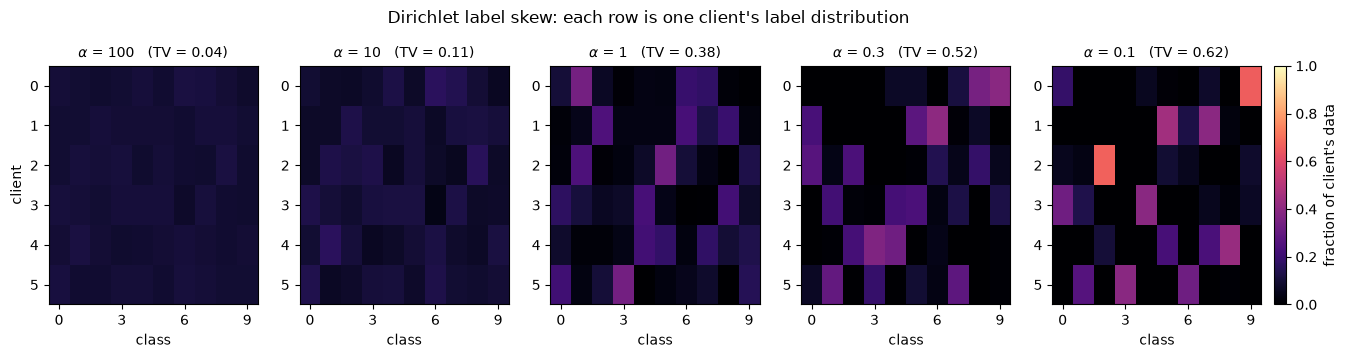

In [9]:
# ---- The canonical figure of this literature: who owns which labels ----
fig, axes = plt.subplots(1, len(ALPHAS), figsize=(16, 3.1))

for ax_, a in zip(axes, ALPHAS):
    M = label_matrix(PARTS[a]).astype(float)
    frac = M / np.maximum(M.sum(1, keepdims=True), 1)      # row-normalize: label MIX per client
    im = ax_.imshow(frac, cmap="magma", vmin=0, vmax=1, aspect="auto")
    ax_.set_xlabel("class")
    ax_.set_title(f"$\\alpha$ = {a:g}   (TV = {skew_tv(PARTS[a]):.2f})", fontsize=10)
    ax_.set_xticks(range(0, N_CLASSES, 3))
    ax_.set_yticks(range(K))
axes[0].set_ylabel("client")
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label="fraction of client's data")
fig.suptitle("Dirichlet label skew: each row is one client's label distribution", y=1.06)

print("Left to right, alpha falls and the rows go from FLAT (every client sees every class")
print("in proportion = IID) to SPIKY (each client is dominated by a couple of classes).")
print()
for a in [100.0, 0.1]:
    M = label_matrix(PARTS[a])
    print(f"alpha = {a:g}:")
    for k in range(K):
        bar = "".join("#" if v >= 0.10 else ("+" if v >= 0.02 else ".")
                      for v in M[k] / max(M[k].sum(), 1))
        print(f"   client {k}  n_k = {M[k].sum():>5}   [{bar}]   "
              f"argmax class {int(np.argmax(M[k]))} holds {M[k].max() / max(M[k].sum(), 1):.0%}")

In [10]:
# ---- The two limits, checked rather than asserted ----
def class_concentration(shards):
    # For each class, the share of its examples held by its largest client, averaged over
    # classes. 1/K = every class spread evenly over the clients; 1.0 = every class on ONE client.
    M = label_matrix(shards).astype(float)
    return float(np.mean(M.max(0) / M.sum(0)))

print("alpha -> infinity should give every client the global label mix; alpha -> 0 should")
print("send each CLASS to (nearly) one client. Both are testable claims.\n")
print(f"{'alpha':>12}  {'label skew (TV)':>15}  {'class concentration':>20}")
print("-" * 52)
for a in [1e4, 1e2, 1.0, 1e-2, 1e-3]:
    sh = dirichlet_partition(Y_all, K, a, seed=3)
    print(f"{a:>12.0e}  {skew_tv(sh):>15.3f}  {class_concentration(sh):>20.3f}")

sh_iid = [np.array(s) for s in np.array_split(np.random.default_rng(0).permutation(len(X_all)), K)]
print(f"\n{'random split':>12}  {skew_tv(sh_iid):>15.3f}  {class_concentration(sh_iid):>20.3f}")
print(f"{'1/K':>12}  {'':>15}  {1 / K:>20.3f}  <- a class spread perfectly evenly")

sh0 = dirichlet_partition(Y_all, K, 1e-3, seed=3)
M0 = label_matrix(sh0)
print(f"\nalpha = 1e-3, the pathological end:")
for k in range(K):
    nz = [int(c) for c in np.where(M0[k] > 0)[0]]
    print(f"   client {k}: n_k = {M0[k].sum():>5}, classes present = {nz}")
print("\n   ^ each CLASS lands on (nearly) one client. But with 10 classes and 6 clients a")
print("     client still holds several classes -- and one client gets no data at all.")
print("     Small alpha does not mean one class per client.")

alpha -> infinity should give every client the global label mix; alpha -> 0 should
send each CLASS to (nearly) one client. Both are testable claims.

       alpha  label skew (TV)   class concentration
----------------------------------------------------
       1e+04            0.004                 0.169
       1e+02            0.036                 0.188
       1e+00            0.379                 0.444
       1e-02            0.798                 0.956
       1e-03            0.793                 0.997

random split            0.033                 0.185
         1/K                                  0.167  <- a class spread perfectly evenly

alpha = 1e-3, the pathological end:
   client 0: n_k =  1178, classes present = [3, 5]
   client 1: n_k =     0, classes present = []
   client 2: n_k =  1222, classes present = [4, 7]
   client 3: n_k =  1846, classes present = [0, 1, 8]
   client 4: n_k =  1146, classes present = [6, 9]
   client 5: n_k =   608, classes present = [2, 5]

 

> **Observe:** one parameter moves the partition from IID-like to highly skewed. At
> $\alpha = 100$ every client sees all 10 classes (TV $\approx 0.04$); at $\alpha = 0.1$ a
> client holds about 4 classes, and its largest class can make up two-thirds of its data
> (TV $\approx 0.62$).
>
> Both limits behave as expected, with two details worth noticing:
>
> - **Large $\alpha$ is *more* uniform than a random split.** At $\alpha = 10^4$ the TV skew
>   is about $0.004$, while a truly random IID split gives about $0.033$. The Dirichlet
>   partition splits each class separately, so it is stratified and lacks the sampling noise
>   of a random split. A large-$\alpha$ baseline is therefore slightly better than IID —
>   negligible here, but it can matter when you are chasing a small effect.
> - **Small $\alpha$ concentrates classes, not clients.** As $\alpha \to 0$ the class
>   concentration approaches $1$: each class lands on (nearly) one client. With 10 classes and
>   6 clients, a client still holds several classes, and one client receives no data.
>
> $\alpha$ also changes client sizes: at $\alpha = 0.1$ clients hold between 492 and 1527
> examples ($3.1\times$). Effects attributed to "non-IID" below include both label skew and
> size imbalance; Exercise 1 separates them.


### 🔬 Exercise 1

**Exercise: separate label skew from size skew.** The Observe cell just admitted a
confound: a Dirichlet partition changes *what* clients own and *how much* they own at the
same time. Fix it.

Write `balanced_dirichlet_partition(Y, K, alpha, seed)` that produces the same *label
skew* as `dirichlet_partition` but gives every client **the same number** of examples (subsample
each client down to the smallest client's size). Then confirm you have what you claim:
report the TV skew (should be roughly preserved) and the size imbalance (should be exactly
1.0×) for $\alpha \in \{100, 1, 0.1\}$.

Why does this matter for reading Section 8's results?


In [11]:
# --- Reference solution (instructor: blank this out for students) ---

def balanced_dirichlet_partition(Y, n_clients, alpha, seed=0):
    # Same Dirichlet label skew, then truncate every client to the smallest client's size.
    # Label MIX is preserved (we subsample uniformly within a client); label COUNTS are not.
    shards = dirichlet_partition(Y, n_clients, alpha, seed=seed)
    m = min(len(s) for s in shards)
    r = np.random.default_rng(seed + 1)
    return [np.sort(r.choice(s, size=m, replace=False)) for s in shards]


print(f"{'alpha':>7}  {'partition':>12}  {'TV skew':>8}  {'n_k min':>8}  {'n_k max':>8}  "
      f"{'imbalance':>10}")
print("-" * 62)
for a in [100.0, 1.0, 0.1]:
    for name, sh in [("dirichlet", dirichlet_partition(Y_all, K, a, seed=3)),
                     ("balanced", balanced_dirichlet_partition(Y_all, K, a, seed=3))]:
        sizes = label_matrix(sh).sum(1)
        print(f"{a:>7.1f}  {name:>12}  {skew_tv(sh):>8.3f}  {sizes.min():>8}  {sizes.max():>8}  "
              f"{sizes.max() / sizes.min():>9.1f}x")

print()
print("The TV skew survives the balancing (we subsampled uniformly WITHIN each client, so")
print("its label MIX is approximately unchanged); the size imbalance becomes exactly 1.0x.")
print()
print("Why it matters for Section 8: with equal n_k, the FedAvg weights n_k/n become 1/K,")
print("so 'weight by size' and 'weight uniformly' coincide and one whole confound is gone.")
print("Any remaining gap between IID and non-IID is then attributable to LABEL skew alone --")
print("which is the thing FedProx and SCAFFOLD actually claim to address. The price is that")
print("you throw away data (here: the largest client loses most of its examples), so the")
print("balanced runs are not comparable to the unbalanced ones in absolute terms -- only")
print("within their own family. Controls cost something. Run them anyway.")

  alpha     partition   TV skew   n_k min   n_k max   imbalance
--------------------------------------------------------------
  100.0     dirichlet     0.036       961      1051        1.1x
  100.0      balanced     0.037       961       961        1.0x
    1.0     dirichlet     0.379       642      1331        2.1x
    1.0      balanced     0.379       642       642        1.0x
    0.1     dirichlet     0.619       492      1527        3.1x
    0.1      balanced     0.617       492       492        1.0x

The TV skew survives the balancing (we subsampled uniformly WITHIN each client, so
its label MIX is approximately unchanged); the size imbalance becomes exactly 1.0x.

Why it matters for Section 8: with equal n_k, the FedAvg weights n_k/n become 1/K,
so 'weight by size' and 'weight uniformly' coincide and one whole confound is gone.
Any remaining gap between IID and non-IID is then attributable to LABEL skew alone --
which is the thing FedProx and SCAFFOLD actually claim to address. 

Read the figure in two directions:
  * Across a ROW (alpha falls): the colour mix inside each bar collapses onto a few
    classes. That is label skew, and it is the same in both rows (compare the TVs).
  * Down a COLUMN (dirichlet -> balanced): bar heights become equal, cut at the
    dotted line. That is the size confound, and only the top row has it.

  alpha =   100: balancing discards 4% of the data
  alpha =     1: balancing discards 36% of the data
  alpha =   0.1: balancing discards 51% of the data

The grey ghosts are the price of the control: the more skewed the partition, the
more uneven the sizes, and the more data the balanced family has to throw away.


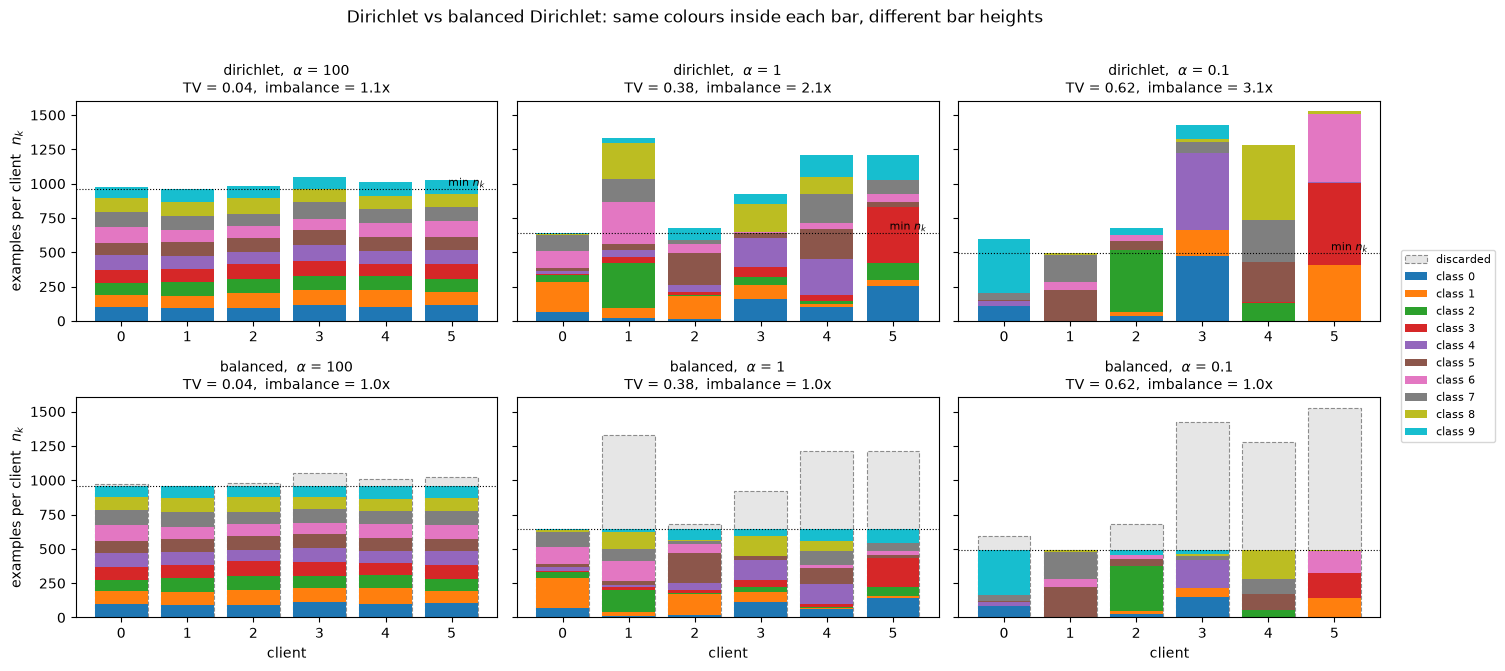

In [ ]:
# --- Reference solution, continued (blank together with the cell above) ---
# The same two partitions as histograms: one bar per client, height = n_k, colour = class.
# Top row: what Dirichlet delivers. Bottom row: after balancing. The grey ghost behind each
# balanced bar is the client's ORIGINAL size -- the data the control throws away.
CMAP = plt.get_cmap("tab10")
ALPHAS_EX = [100.0, 1.0, 0.1]

fig, axes = plt.subplots(2, len(ALPHAS_EX), figsize=(14, 6.6), sharey=True)
discarded = {}
for j, a in enumerate(ALPHAS_EX):
    sh_d = dirichlet_partition(Y_all, K, a, seed=3)
    sh_b = balanced_dirichlet_partition(Y_all, K, a, seed=3)
    n_orig = label_matrix(sh_d).sum(1)
    discarded[a] = 1 - label_matrix(sh_b).sum() / n_orig.sum()
    for i, (name, sh) in enumerate([("dirichlet", sh_d), ("balanced", sh_b)]):
        ax_ = axes[i, j]
        M = label_matrix(sh)
        if name == "balanced":
            ax_.bar(range(K), n_orig, width=0.8, color="0.9", edgecolor="0.55",
                    linestyle="--", linewidth=0.8, label="discarded")
        bottom = np.zeros(K)
        for c in range(N_CLASSES):
            ax_.bar(range(K), M[:, c], bottom=bottom, width=0.8, color=CMAP(c),
                    label=f"class {c}")
            bottom += M[:, c]
        ax_.axhline(n_orig.min(), color="k", lw=0.8, ls=":")   # smallest client = the cut line
        sizes = M.sum(1)
        ax_.set_title(f"{name},  $\\alpha$ = {a:g}\nTV = {skew_tv(sh):.2f},  "
                      f"imbalance = {sizes.max() / sizes.min():.1f}x", fontsize=10)
        ax_.set_xticks(range(K))
        if i == 1:
            ax_.set_xlabel("client")
    axes[0, j].text(K - 0.5, n_orig.min(), " min $n_k$", va="bottom", ha="right", fontsize=8)
axes[0, 0].set_ylabel("examples per client  $n_k$")
axes[1, 0].set_ylabel("examples per client  $n_k$")
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
fig.suptitle("Dirichlet vs balanced Dirichlet: same colours inside each bar, "
             "different bar heights", y=1.01)
fig.tight_layout()

print("Read the figure in two directions:")
print("  * Across a ROW (alpha falls): the colour mix inside each bar collapses onto a few")
print("    classes. That is label skew, and it is the same in both rows (compare the TVs).")
print("  * Down a COLUMN (dirichlet -> balanced): bar heights become equal, cut at the")
print("    dotted line. That is the size confound, and only the top row has it.")
print()
for a in ALPHAS_EX:
    print(f"  alpha = {a:>5g}: balancing discards {discarded[a]:.0%} of the data")
print()
print("The grey ghosts are the price of the control: the more skewed the partition, the")
print("more uneven the sizes, and the more data the balanced family has to throw away.")

---

## 3. Measuring client drift — three instruments

We showed drift on a simple quadratic and used $\alpha$ to control label skew. Now we
measure drift in our **neural network** as $\alpha$ changes. We use several measures because
any single measure can miss part of the picture.

Each client starts from the broadcast model $\theta^{(r)}$ and makes an update:

$$\Delta_k = \theta_k - \theta^{(r)}, \qquad \bar\Delta = \sum_k p_k \Delta_k.$$

Here, $\bar\Delta$ is the update the server applies. We measure client disagreement in three ways:

| Measure | Simple meaning | Limitation |
|---|---|---|
| **Parameter spread** | How far apart are the client models? | Larger learning rates or more local steps can increase it, even under IID data. |
| **Update cosine** | Do clients move in the same direction as the server update? | Matching directions can hide very different update sizes. |
| **Relative update variance** | How much do client updates differ compared with the shared update? | It can become large simply because the shared update is small. |

Higher spread, lower cosine, and higher relative variance generally suggest more
disagreement. Read them together.

Theory often measures gradient disagreement at the same model. Our measurements use updates
after several local steps, so they are practical indicators—not the exact theoretical
quantity. We will use them to see how disagreement changes with $\alpha$.

In [12]:
# ---------------- The Stage 3 local-work engine, carried over from Week 7 ----------------
# scan over the tau local steps (trip count = leading axis, so sweeping tau does not grow
# the compiled program), vmap over the K clients (a client axis is a transformation, not a
# rewrite). `mu` is traced: mu=0.0 is FedAvg, mu>0 is FedProx. Section 5.

def local_step(carry, batch):
    params, bn, opt_state, anchor, mu = carry
    x, y = batch

    def objective(p, s):
        l, s2 = loss_fn(eqx.combine(p, static0), s, x, y)
        # ------------- FedProx, in its entirety -------------
        prox = 0.5 * mu * sum(jnp.sum((a - b) ** 2)
                              for a, b in zip(jax.tree.leaves(p), jax.tree.leaves(anchor)))
        # ----------------------------------------------------
        return l + prox, s2

    (loss, bn_new), grads = jax.value_and_grad(objective, has_aux=True)(params, bn)
    updates, opt_new = optimizer.update(grads, opt_state, params)
    return (eqx.apply_updates(params, updates), bn_new, opt_new, anchor, mu), loss


def local_block(params, bn, opt_state, xs, ys, mu):
    # tau local steps for ONE client. anchor = theta^(r), the round's starting point.
    (p, b, o, _, _), losses = jax.lax.scan(
        local_step, (params, bn, opt_state, params, mu), (xs, ys))
    return p, b, o, jnp.mean(losses)


run_clients = eqx.filter_jit(jax.vmap(local_block, in_axes=(0, 0, 0, 0, 0, None)))

def broadcast(tree, n):
    return jax.tree.map(lambda a: jnp.broadcast_to(a, (n,) + a.shape), tree)

def aggregate(tree, w):
    # THE aggregation: weighted mean over the client axis. This one line is Local SGD, and
    # it is FedAvg, and (Section 6) it is SCAFFOLD too. Only the recipe for `w` differs.
    return jax.tree.map(lambda leaf: jnp.tensordot(w, leaf, axes=1), tree)

def global_norm(tree):
    return jnp.sqrt(sum(jnp.sum(x ** 2) for x in jax.tree.leaves(tree)))

def flat_leaves(tree):
    return jnp.concatenate([l.ravel() for l in jax.tree.leaves(tree)])


def client_batches(x, y, tau, rnd, pid, B=B_LOCAL):
    # tau batches of size B, drawn from ONE client's OWN data. `x`, `y` are that client's
    # arrays and nothing else -- which is what makes this function usable verbatim inside a
    # real Flower client in Section 4, where the global dataset does not exist.
    # Seeded by (round, client) so the vmap harness and the Flower run draw IDENTICAL
    # batches: that is what makes Section 4's cross-check meaningful.
    # Note every client draws B per step regardless of n_k -- a modelling choice, flagged in
    # Week 7's Further Exercise 5.
    r = np.random.default_rng(1000 * rnd + pid)
    pick = r.choice(len(y), size=(tau, B), replace=True)
    return jnp.asarray(x[pick]), jnp.asarray(y[pick])


def sample_batches(shards, tau, rnd, B=B_LOCAL):
    # The in-process harness: stack the per-client batches along a leading client axis.
    out = [client_batches(Xh[s], Yh[s], tau, rnd, k, B) for k, s in enumerate(shards)]
    return (jnp.stack([o[0] for o in out]), jnp.stack([o[1] for o in out]))


print(f"tau = {TAU} local steps/round, batch {B_LOCAL}, SGD lr = {LR}, K = {K} clients")

tau = 16 local steps/round, batch 16, SGD lr = 0.4, K = 6 clients


In [13]:
def drift_instruments(shards, rnd=0, mu=0.0, params=None, bn=None):
    # Run ONE round from a common start and measure how far apart the clients ended up.
    p_start = params0 if params is None else params
    b_start = bn0 if bn is None else bn
    Kk = len(shards)
    sizes = np.array([len(s) for s in shards], dtype=np.float64)
    w = jnp.asarray(sizes / sizes.sum(), dtype=jnp.float32)

    xs, ys = sample_batches(shards, TAU, rnd)
    cp, cb, co, _ = run_clients(broadcast(p_start, Kk), broadcast(b_start, Kk),
                                broadcast(opt0, Kk), xs, ys, mu)

    # Delta_k = theta_k - theta^(r), flattened to one vector per client
    D = jax.vmap(lambda t: flat_leaves(jax.tree.map(lambda a, s: a - s, t, p_start)))(cp)
    d_bar = jnp.tensordot(w, D, axes=1)                        # the aggregated update

    # 1. parameter spread
    theta_bar = jnp.tensordot(w, jax.vmap(flat_leaves)(cp), axes=1)
    spread = float(jnp.mean(jnp.linalg.norm(jax.vmap(flat_leaves)(cp) - theta_bar, axis=1)))
    # 2. cosine between each client's update and the aggregated update
    cos = jax.vmap(lambda d: jnp.dot(d, d_bar) /
                   (jnp.linalg.norm(d) * jnp.linalg.norm(d_bar) + 1e-12))(D)
    # 3. update variance, normalized by the signal  (= empirical gradient dissimilarity)
    var = float(jnp.sum(w * jnp.sum((D - d_bar) ** 2, axis=1)) /
                (jnp.sum(d_bar ** 2) + 1e-12))
    # also: how big is the aggregated update relative to a typical client's?
    shrink = float(jnp.linalg.norm(d_bar) / jnp.mean(jnp.linalg.norm(D, axis=1)))
    return dict(spread=spread, cos=float(jnp.mean(cos)), cos_min=float(jnp.min(cos)),
                var=var, shrink=shrink)


print(f"one round of tau = {TAU} local steps from the SAME initial model, per alpha")
print(f"{'alpha':>8}  {'TV skew':>8}  {'param spread':>13}  {'mean cos':>9}  {'min cos':>8}  "
      f"{'update var':>11}  {'||d_bar||/||d_k||':>18}")
print("-" * 88)
drift_rows = []
for a in ALPHAS:
    d = drift_instruments(PARTS[a])
    d["alpha"] = a; d["tv"] = skew_tv(PARTS[a])
    drift_rows.append(d)
    print(f"{a:>8.1f}  {d['tv']:>8.3f}  {d['spread']:>13.4f}  {d['cos']:>9.3f}  "
          f"{d['cos_min']:>8.3f}  {d['var']:>11.3f}  {d['shrink']:>18.3f}")

print("\nAll three instruments move the same way as alpha falls: spread up, cosine down,")
print(f"update variance up. The variance moves most: "
      f"{drift_rows[-1]['var'] / drift_rows[0]['var']:.0f}x from alpha=100 to alpha=0.1.")

one round of tau = 16 local steps from the SAME initial model, per alpha
   alpha   TV skew   param spread   mean cos   min cos   update var   ||d_bar||/||d_k||
----------------------------------------------------------------------------------------


   100.0     0.036         0.4889      0.859     0.821        0.374               0.857
    10.0     0.114         0.6406      0.776     0.681        0.666               0.784


     1.0     0.379         1.4671      0.493     0.337        3.174               0.483
     0.3     0.523         1.9444      0.402     0.098        5.002               0.403


     0.1     0.619         2.2112      0.316    -0.012        5.783               0.391

All three instruments move the same way as alpha falls: spread up, cosine down,
update variance up. The variance moves most: 15x from alpha=100 to alpha=0.1.


In [14]:
# Drift is not a property of a single round: it compounds. Measure it ALONG a run.
def run_fed(rounds, shards, mu=0.0, tau=TAU, track_drift=True, seed=0):
    # THE federated loop. Defaults = FedAvg with full participation and n_k/n weighting.
    # This is Week 7's run_distributed with the knobs we need today.
    Kk = len(shards)
    sizes = np.array([len(s) for s in shards], dtype=np.float64)
    w = jnp.asarray(sizes / sizes.sum(), dtype=jnp.float32)
    sp, sb, so = params0, bn0, opt0
    hist = []
    for r in range(rounds):
        # 1. broadcast theta^(r)
        wp, wb, wo = broadcast(sp, Kk), broadcast(sb, Kk), broadcast(so, Kk)
        # 2. tau local steps on each client's own data
        xs, ys = sample_batches(shards, tau, r)
        cp, cb, co, tl = run_clients(wp, wb, wo, xs, ys, mu)
        # 3. instruments, measured BEFORE aggregation
        d = {}
        if track_drift:
            D = jax.vmap(lambda t: flat_leaves(jax.tree.map(lambda a, s: a - s, t, sp)))(cp)
            d_bar = jnp.tensordot(w, D, axes=1)
            theta_bar = jnp.tensordot(w, jax.vmap(flat_leaves)(cp), axes=1)
            d["spread"] = float(jnp.mean(jnp.linalg.norm(jax.vmap(flat_leaves)(cp) - theta_bar, axis=1)))
            d["cos"] = float(jnp.mean(jax.vmap(lambda dd: jnp.dot(dd, d_bar) /
                             (jnp.linalg.norm(dd) * jnp.linalg.norm(d_bar) + 1e-12))(D)))
            d["var"] = float(jnp.sum(w * jnp.sum((D - d_bar) ** 2, axis=1)) /
                             (jnp.sum(d_bar ** 2) + 1e-12))
        # 4. aggregate. NOTE we average the batch statistics too -- see the Section 4 caveat.
        sp, sb, so = aggregate(cp, w), aggregate(cb, w), aggregate(co, w)
        l, a = evaluate(sp, sb, X_te, Y_te)
        hist.append(dict(rnd=r, loss=float(l), acc=float(a), train=float(jnp.mean(tl)), **d))
    return hist


R_DRIFT = 12
drift_runs = {a: run_fed(R_DRIFT, PARTS[a]) for a in ALPHAS}
print(f"{len(ALPHAS)} runs x {R_DRIFT} rounds x tau={TAU}")
print(f"\n{'alpha':>8}  {'final spread':>13}  {'final cos':>10}  {'final var':>10}  "
      f"{'test loss':>10}  {'test acc':>9}")
print("-" * 68)
for a in ALPHAS:
    h = drift_runs[a][-1]
    print(f"{a:>8.1f}  {h['spread']:>13.4f}  {h['cos']:>10.3f}  {h['var']:>10.3f}  "
          f"{h['loss']:>10.4f}  {h['acc']:>9.3f}")

5 runs x 12 rounds x tau=16

   alpha   final spread   final cos   final var   test loss   test acc
--------------------------------------------------------------------
   100.0         0.7822       0.734       0.861      0.8392      0.800
    10.0         0.8452       0.699       1.041      0.8391      0.794
     1.0         1.2779       0.506       2.844      0.8131      0.873
     0.3         1.5627       0.404       4.691      0.9379      0.737
     0.1         1.8794       0.293       9.714      1.3238      0.566


from alpha=100 (nearly IID) to alpha=0.1 (strongly skewed), at the last round:
   parameter spread : 0.7822 -> 1.8794   (2.4x)
   mean cosine      : 0.734 -> 0.293
   update variance  : 0.861 -> 9.714   (11.3x)

And the control that makes it a measurement rather than a story: at alpha=100 the
drift is NOT zero (spread 0.7822, cosine 0.734). IID clients also
drift -- on minibatch NOISE. What alpha adds is drift that is BIASED (Section 1).

One thing NOT to read off this table: the accuracy column is not yet ordered by
alpha ([0.8, 0.794, 0.873, 0.737, 0.566] for alpha = ['100', '10', '1', '0.3', '0.1']).
After only 12 rounds these runs are far from converged. One plausible reason
for the early lead of mild skew: each client's LOCAL problem has fewer effective
classes, so early local progress is faster (not tested here). Section 8 runs long
enough for the ordering to settle. The DRIFT columns are what this section
measures, and those are monotone in alpha from round 0.


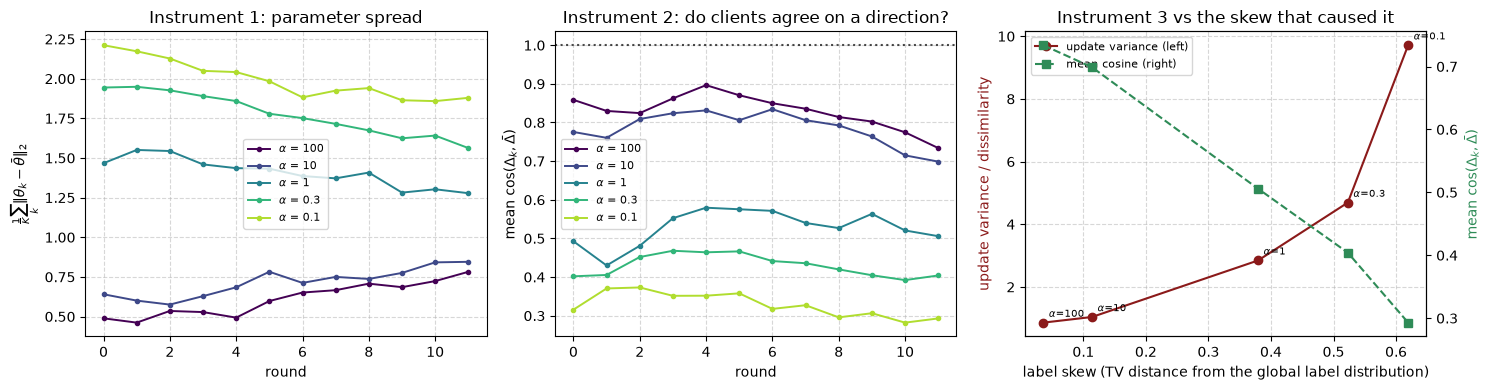

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.0))
cols = plt.cm.viridis(np.linspace(0, 0.88, len(ALPHAS)))

for c, a in zip(cols, ALPHAS):
    h = drift_runs[a]
    ax[0].plot([d["rnd"] for d in h], [d["spread"] for d in h], "o-", color=c, ms=3, lw=1.4,
               label=f"$\\alpha$ = {a:g}")
ax[0].set_xlabel("round"); ax[0].set_ylabel(r"$\frac{1}{K}\sum_k \|\theta_k - \bar{\theta}\|_2$")
ax[0].set_title("Instrument 1: parameter spread")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5)

for c, a in zip(cols, ALPHAS):
    h = drift_runs[a]
    ax[1].plot([d["rnd"] for d in h], [d["cos"] for d in h], "o-", color=c, ms=3, lw=1.4,
               label=f"$\\alpha$ = {a:g}")
ax[1].axhline(1.0, color="k", ls=":", alpha=0.7)
ax[1].set_xlabel("round")
ax[1].set_ylabel(r"mean $\cos(\Delta_k, \bar{\Delta})$")
ax[1].set_title("Instrument 2: do clients agree on a direction?")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5)

tvs = [skew_tv(PARTS[a]) for a in ALPHAS]
v_final = [drift_runs[a][-1]["var"] for a in ALPHAS]
s_final = [drift_runs[a][-1]["spread"] for a in ALPHAS]
c_final = [drift_runs[a][-1]["cos"] for a in ALPHAS]
ax2 = ax[2].twinx()
ax[2].plot(tvs, v_final, "o-", color="#8b1a1a", label="update variance (left)")
ax2.plot(tvs, c_final, "s--", color="#2e8b57", label="mean cosine (right)")
ax[2].set_xlabel("label skew (TV distance from the global label distribution)")
ax[2].set_ylabel("update variance / dissimilarity", color="#8b1a1a")
ax2.set_ylabel(r"mean $\cos(\Delta_k, \bar{\Delta})$", color="#2e8b57")
ax[2].set_title("Instrument 3 vs the skew that caused it")
ax[2].grid(True, ls="--", alpha=0.5)
for a, x_, y_ in zip(ALPHAS, tvs, v_final):
    ax[2].annotate(f"$\\alpha$={a:g}", (x_, y_), fontsize=7.5,
                   textcoords="offset points", xytext=(4, 4))
h1, l1 = ax[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax[2].legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")

plt.tight_layout()

print(f"from alpha=100 (nearly IID) to alpha=0.1 (strongly skewed), at the last round:")
print(f"   parameter spread : {s_final[0]:.4f} -> {s_final[-1]:.4f}   ({s_final[-1] / s_final[0]:.1f}x)")
print(f"   mean cosine      : {c_final[0]:.3f} -> {c_final[-1]:.3f}")
print(f"   update variance  : {v_final[0]:.3f} -> {v_final[-1]:.3f}   ({v_final[-1] / v_final[0]:.1f}x)")
print("\nAnd the control that makes it a measurement rather than a story: at alpha=100 the")
print(f"drift is NOT zero (spread {s_final[0]:.4f}, cosine {c_final[0]:.3f}). IID clients also")
print("drift -- on minibatch NOISE. What alpha adds is drift that is BIASED (Section 1).")
print()
print("One thing NOT to read off this table: the accuracy column is not yet ordered by")
accs_now = [drift_runs[a][-1]["acc"] for a in ALPHAS]
print(f"alpha ({[round(x, 3) for x in accs_now]} for alpha = {[f'{a:g}' for a in ALPHAS]}).")
print(f"After only {R_DRIFT} rounds these runs are far from converged. One plausible reason")
print("for the early lead of mild skew: each client's LOCAL problem has fewer effective")
print("classes, so early local progress is faster (not tested here). Section 8 runs long")
print("enough for the ordering to settle. The DRIFT columns are what this section")
print("measures, and those are monotone in alpha from round 0.")

> **Observe:** smaller $\alpha$ means stronger label skew, and all three measures show more
> client disagreement:
>
> - **Spread** increases about $2.4\times$. It is already nonzero with nearly IID data
>   because minibatch noise separates client models.
> - **Mean cosine** drops from $0.73$ to $0.29$. Clients move in less aligned directions. At
>   $\alpha = 0.1$, one client's update is almost perpendicular to the server update.
> - **Relative update variance** increases about $11\times$. This is the strongest change,
>   but remember: the ratio can also rise when the shared update shrinks.
>
> Nonzero drift alone does not prove a non-IID problem. Compare against the nearly IID
> baseline. These measurements mix noise and systematic disagreement; Section 1's noiseless
> example demonstrated bias directly.


---

## 4. Stage 4: the same code, now under Flower

Everything so far has been a `vmap` over a client axis — a *simulation of a federation* that
runs in one process, shares one memory space, and could reach into any client's data at any
time. That is fine for studying the optimization, but it does not *enforce* what federated
learning assumes: that clients run separately and never see each other's data.

**Spine Stage 4** is where the codebase crosses that line. The same Equinox model, the same
Optax optimizer, the same `local_block` — but now:

- each client is a **separate process**, holding only its own shard;
- the only thing that crosses between them is a **list of NumPy arrays**;
- the aggregation is done by **Flower's own `FedAvg` strategy**, not by our `aggregate`.

Nothing about the *mathematics* changes. Everything about what you are allowed to assume
does.

### The boundary is NumPy, and that is the interesting part

Flower's wire format is `Parameters` ≈ a list of NumPy arrays. Our model is an Equinox
PyTree. So we need `PyTree → List[np.ndarray] → PyTree`, and there are two ways to do it:

1. `jax.flatten_util.ravel_pytree` — one flat vector plus an `unravel` closure.
2. An explicit `jax.tree.leaves` order — flatten by hand, reassemble against a **reference
   tree** you already have.

We use **(2)**, and not for style. Read the trap list below.

### The traps, all of them paid for in build cycles

1. **`run_simulation` returns `None`** in flwr 1.32 — there is no `History` object to read.
   Capture what you need yourself by subclassing the strategy and overriding
   `aggregate_fit`. This is not a workaround to resent; it is the natural hook, and Weeks
   10–13 all live in it (compression, Byzantine injection, robust aggregation).
2. **Without `min_available_clients=K`, round 1 silently samples fewer clients** than later
   rounds — the Ray workers have not all registered yet. Your round-1 numbers are then
   quietly wrong, with no error.
3. **`run_simulation` is deprecated** in favour of the `flwr run` CLI. It still works, and it
   is the right choice *in a notebook*: `flwr run` needs a Flower App project scaffold with a
   `pyproject.toml`, which a notebook cell cannot be. On the GPU node, the real Lab 7 uses
   `flwr run`.
4. **`backend_config` must silence Ray** (`log_to_driver: False`, `include_dashboard:
   False`) or the notebook output drowns.
5. **The strategy API needs no Ray at all.** `FedAvg().aggregate_fit(...)` can be driven
   directly with hand-built `FitRes` objects. We use this below to check the aggregation
   *math* cheaply — and, crucially, to license using our fast `vmap` harness for the sweeps.
6. **Do not ship an `eqx.Module` subclass you defined in a notebook cell.** This one cost the
   most and is the reason `make_model` is a `Sequential` of library layers. Details below —
   it is worth your time.


### Trap 6: notebook-defined models can break in workers

Ray sends client code to separate worker processes. A custom `eqx.Module` defined in a
notebook may be rebuilt incorrectly there, breaking its initialization or PyTree structure.

In our setup, this caused errors such as:

```text
FrozenInstanceError: cannot assign to field 'conv1'
TypeError: '_Missing' object is not subscriptable
```

More confusingly, the worker sometimes saw **zero parameter leaves**. The failure appeared
later in the forward pass, far from the serialization step that caused it.

Two practical fixes:

- **In the notebook:** compose the model from importable library classes such as
  `eqx.nn.Sequential` and `eqx.nn.Conv2d`. We keep the architecture but change how it is
  packaged.
- **In the full lab:** define the custom model in a Python module that every worker can
  import. This is why `flwr run` expects a packaged project with a `pyproject.toml` (Trap 3).

We also avoid sending `ravel_pytree`'s reconstruction closure, which captures a tree
definition. Instead, each worker builds the tree definition locally from a reference model.

**The rule:** send NumPy parameter arrays across the boundary, and reconstruct the model
using code available inside each worker.


In [16]:
from flwr.client import ClientApp, NumPyClient
from flwr.server import ServerApp, ServerAppComponents, ServerConfig
from flwr.server.strategy import FedAvg as FlwrFedAvg
from flwr.simulation import run_simulation
from flwr.common import (Context, ndarrays_to_parameters, parameters_to_ndarrays,
                         FitRes, Status, Code)

# ---------------- The JAX <-> Flower boundary ----------------
# Explicit leaf order, reassembled against a REFERENCE tree. No treedef is ever pickled.

def tree_to_flat(tree):
    # PyTree -> one flat float32 NumPy vector, in jax.tree.leaves order.
    return np.concatenate([np.asarray(l).ravel() for l in jax.tree.leaves(tree)]).astype(np.float32)

def flat_to_tree(ref, flat):
    # flat NumPy vector -> PyTree shaped like `ref`. `ref` is rebuilt locally in whichever
    # process calls this, so no structure crosses the wire -- only numbers.
    leaves, treedef = jax.tree.flatten(ref)
    out, i = [], 0
    for l in leaves:
        n = l.size
        out.append(jnp.asarray(flat[i:i + n]).astype(l.dtype).reshape(l.shape))
        i += n
    return jax.tree.unflatten(treedef, out)

def pack(params, bn):
    # The payload. TWO arrays, not one: the four states stay legible on the wire.
    #   [0] model parameters  [1] batch statistics
    # opt_state and the PRNG key do NOT travel -- they are local by construction.
    return [tree_to_flat(params), tree_to_flat(bn)]

def unpack(nds):
    return flat_to_tree(params0, nds[0]), flat_to_tree(bn0, nds[1])


# Round-trip check: this must be the identity, or nothing below means anything.
_p, _b = unpack(pack(params0, bn0))
d1 = max(float(jnp.max(jnp.abs(a - b))) for a, b in zip(jax.tree.leaves(_p), jax.tree.leaves(params0)))
d2 = max(float(jnp.max(jnp.abs(a - b))) for a, b in zip(jax.tree.leaves(_b), jax.tree.leaves(bn0)))
print(f"payload      : {len(pack(params0, bn0))} arrays -- "
      f"params {pack(params0, bn0)[0].shape}, bn {pack(params0, bn0)[1].shape}")
print(f"bytes/round  : {sum(a.nbytes for a in pack(params0, bn0)):,} down + same up, per client")
print(f"round trip   : params max|diff| {d1:.1e}   bn max|diff| {d2:.1e}   identity: "
      f"{d1 == 0.0 and d2 == 0.0}")
print(f"\nThe int32 BatchNorm counter survives too -- flat_to_tree casts each leaf back to")
print(f"its reference dtype: {[str(l.dtype) for l in jax.tree.leaves(bn0)]}")

payload      : 2 arrays -- params (914,), bn (34,)
bytes/round  : 3,792 down + same up, per client
round trip   : params max|diff| 0.0e+00   bn max|diff| 0.0e+00   identity: True

The int32 BatchNorm counter survives too -- flat_to_tree casts each leaf back to
its reference dtype: ['int32', 'float32', 'float32', 'int32', 'float32', 'float32']


> **Caveat: we also average BatchNorm statistics.**
>
> Our code sends BatchNorm running statistics to the server, and Flower's `FedAvg` averages
> them alongside the model parameters — standard FedAvg behaviour. Under non-IID data this is
> questionable: a batch statistic is not a learned parameter but a summary of one client's
> input distribution, so the average describes a distribution that no client has.
>
> **FedBN** (Week 11) keeps BatchNorm layers local instead.
>
> We cannot evaluate that choice here: our BatchNorm uses `mode="batch"`, which normalizes
> with the current batch — even during evaluation. The running statistics therefore never
> affect the model's output, so keeping them local or averaging them gives identical results.
> Week 11 uses a setup that can measure the difference.


In [17]:
# ---------------- Trap 5: the aggregation math, with no Ray at all ----------------
# FedAvg's aggregation rule is  theta <- sum_k (n_k / sum_j n_j) theta_k.  Check it on a
# case you can do in your head before trusting it on the real model.

def fake_fitres(vec, n):
    return FitRes(status=Status(code=Code.OK, message=""),
                  parameters=ndarrays_to_parameters([np.asarray(vec, dtype=np.float32)]),
                  num_examples=n, metrics={})

toy = [(None, fake_fitres([1.0], 10)), (None, fake_fitres([3.0], 30))]
agg = parameters_to_ndarrays(FlwrFedAvg().aggregate_fit(1, toy, [])[0])[0]
print(f"clients: value 1.0 with n=10, value 3.0 with n=30")
print(f"Flower  : {float(agg[0])}")
print(f"by hand : {(10 * 1.0 + 30 * 3.0) / 40}   <- n_k/n weighting, NOT the plain mean (2.0)")
print(f"exact   : {float(agg[0]) == 2.5}\n")

# ---- And now the load-bearing check: does Flower's FedAvg agree with OUR vmap aggregate,
# ---- on the real model, after real local training? If yes, we may use the fast harness
# ---- for the sweeps and reserve run_simulation for the lifecycle.
SHARDS = PARTS[0.3]
sizes = np.array([len(s) for s in SHARDS], dtype=np.float64)
w_size = jnp.asarray(sizes / sizes.sum(), dtype=jnp.float32)

xs, ys = sample_batches(SHARDS, TAU, 0)
cp, cb, co, _ = run_clients(broadcast(params0, K), broadcast(bn0, K), broadcast(opt0, K),
                            xs, ys, 0.0)
ours = tree_to_flat(aggregate(cp, w_size))

res = [(None, FitRes(status=Status(code=Code.OK, message=""),
                     parameters=ndarrays_to_parameters([tree_to_flat(jax.tree.map(lambda a: a[k], cp))]),
                     num_examples=int(sizes[k]), metrics={}))
       for k in range(K)]
flwr_agg = parameters_to_ndarrays(FlwrFedAvg().aggregate_fit(1, res, [])[0])[0]

d = float(np.max(np.abs(flwr_agg - np.asarray(ours))))
print(f"K = {K} real clients, n_k = {sizes.astype(int)}, sum = {int(sizes.sum())}")
print(f"Flower's FedAvg.aggregate_fit  vs  our vmap aggregate(cp, n_k/n)")
print(f"   max |difference| over {N_PARAMS:,} parameters : {d:.2e}")
print(f"   identical to float32 noise                 : {d < 1e-5}")
print("\nThis is the permission slip for the rest of the notebook. The two harnesses compute")
print("the SAME aggregation, so the alpha/mu sweeps may use the fast in-process vmap while")
print("run_simulation carries the real client/server lifecycle. Every table below says which.")

clients: value 1.0 with n=10, value 3.0 with n=30
Flower  : 2.5
by hand : 2.5   <- n_k/n weighting, NOT the plain mean (2.0)
exact   : True



K = 6 real clients, n_k = [ 837  673 1423  884  997 1186], sum = 6000
Flower's FedAvg.aggregate_fit  vs  our vmap aggregate(cp, n_k/n)
   max |difference| over 914 parameters : 1.19e-07
   identical to float32 noise                 : True

This is the permission slip for the rest of the notebook. The two harnesses compute
the SAME aggregation, so the alpha/mu sweeps may use the fast in-process vmap while
run_simulation carries the real client/server lifecycle. Every table below says which.


In [18]:
# ---------------- The real thing: FedAvg under Flower ----------------
HISTORY = []                       # trap 1: run_simulation returns None. Record it yourself.
ALPHA_FLWR = 0.3
FLWR_SHARDS = PARTS[ALPHA_FLWR]
FLWR_ROUNDS = 5


class RecordingFedAvg(FlwrFedAvg):
    # Trap 1's hook -- and the hook Weeks 10-13 live in. Everything a strategy can do
    # (compress, filter Byzantine clients, robustly aggregate) happens right here.
    def aggregate_fit(self, rnd, results, failures):
        params, metrics = super().aggregate_fit(rnd, results, failures)   # <- the n_k/n mean
        if params is not None:
            p, b = unpack(parameters_to_ndarrays(params))
            l, a = evaluate(p, b, X_te, Y_te)
            HISTORY.append(dict(rnd=rnd, n_clients=len(results), loss=float(l), acc=float(a),
                                n_examples=sum(r.num_examples for _, r in results)))
        return params, metrics


class JaxFlowerClient(NumPyClient):
    # A real Flower client. It knows its own shard and NOTHING else -- no X_all, no other
    # client, no server state. That constraint is the entire subject of the second half of
    # this course, and here it is finally enforced by the process boundary rather than by
    # our good intentions.
    def __init__(self, pid):
        self.pid = pid
        s = FLWR_SHARDS[pid]
        self.x, self.y = Xh[s], Yh[s]        # <- THIS CLIENT'S DATA. There is no X_all here.

    def fit(self, parameters, config):
        params, bn = unpack(parameters)                 # 1. wire -> PyTree
        # opt_state is LOCAL by construction: rebuilt here, never transmitted. For plain SGD
        # it is empty, so rebuilding == receiving. With momentum it would not be, and "what
        # happens to the optimizer state at aggregation?" becomes a real design question
        # (Week 7, Further Exercise 4; FedOpt).
        opt_state = optimizer.init(params)
        rnd = int(config["round"])
        xs, ys = client_batches(self.x, self.y, TAU, rnd, self.pid)   # same fn as the harness
        params, bn, _, loss = local_block(params, bn, opt_state, xs, ys, 0.0)  # 2. Stage 1-3 code, UNTOUCHED
        return pack(params, bn), len(self.y), {"loss": float(loss)}            # 3. PyTree -> wire, + n_k


def client_fn(ctx: Context):
    return JaxFlowerClient(int(ctx.node_config["partition-id"])).to_client()   # <- how a client learns who it is


def server_fn(ctx: Context):
    return ServerAppComponents(
        strategy=RecordingFedAvg(
            initial_parameters=ndarrays_to_parameters(pack(params0, bn0)),
            fraction_fit=1.0,
            min_fit_clients=K,
            min_available_clients=K,          # <- trap 2: without this, round 1 is quietly wrong
            fraction_evaluate=0.0,            #    we evaluate centrally in aggregate_fit instead
            # Flower numbers rounds from 1; our vmap harness loops from 0. `client_batches`
            # is seeded by the round, so without this -1 the two harnesses draw DIFFERENT
            # batches and the cross-check below silently compares two different experiments.
            # It still "agrees" -- to about 1e-2, which looks like noise and is not.
            on_fit_config_fn=lambda r: {"round": r - 1}),
        config=ServerConfig(num_rounds=FLWR_ROUNDS))


In [19]:
print(f"Flower {flwr.__version__}: {K} supernodes x {FLWR_ROUNDS} rounds, "
      f"alpha = {ALPHA_FLWR}, tau = {TAU}")
print("(the real Lab 7 runs 100 clients on the GPU node via `flwr run`)")
print("\nA DEPRECATION warning for run_simulation is expected -- see trap 3.\n")

t0 = time.perf_counter()
run_simulation(
    server_app=ServerApp(server_fn=server_fn),
    client_app=ClientApp(client_fn=client_fn),
    num_supernodes=K,
    backend_config={"init_args": {"num_cpus": 4, "log_to_driver": False,
                                  "include_dashboard": False}},   # <- trap 4
)
print(f"\nsimulation wall-clock: {time.perf_counter() - t0:.1f}s "
      f"({K} client processes, each JIT-compiling its own copy -- a CPU number, "
      f"not an FL number)")


            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        


INFO :      Starting Flower ServerApp, config: num_rounds=5, no round_timeout


INFO :      


INFO :      [INIT]


INFO :      Using initial global parameters provided by strategy


INFO :      Starting evaluation of initial global parameters


... (31 outputs left out)

INFO :      [SUMMARY]


INFO :      Run finished 5 round(s) in 15.69s


INFO :      



simulation wall-clock: 19.0s (6 client processes, each JIT-compiling its own copy -- a CPU number, not an FL number)


In [20]:
print(f"{'round':>7}  {'clients':>8}  {'examples':>9}  {'test loss':>10}  {'test acc':>9}")
print("-" * 50)
for h in HISTORY:
    print(f"{h['rnd']:>7}  {h['n_clients']:>8}  {h['n_examples']:>9}  {h['loss']:>10.4f}  "
          f"{h['acc']:>9.3f}")

n_seen = {h["n_clients"] for h in HISTORY}
print(f"\nclients per round: {sorted(n_seen)}  <- trap 2 check: all rounds sampled "
      f"{'the same number' if len(n_seen) == 1 else 'DIFFERENT numbers (min_available_clients?)'}")
print(f"examples per round: {sorted({h['n_examples'] for h in HISTORY})} out of {len(X_all)} "
      f"-- full participation, so every example is represented every round")

# Does the federated run match the in-process harness? Same seeds, same everything.
ref = run_fed(FLWR_ROUNDS, FLWR_SHARDS, mu=0.0, track_drift=False)
print(f"\n{'round':>7}  {'Flower loss':>12}  {'vmap harness loss':>18}  {'|difference|':>13}")
print("-" * 56)
for h, r_ in zip(HISTORY, ref):
    print(f"{h['rnd']:>7}  {h['loss']:>12.5f}  {r_['loss']:>18.5f}  {abs(h['loss'] - r_['loss']):>13.2e}")
worst = max(abs(h["loss"] - r_["loss"]) for h, r_ in zip(HISTORY, ref))
print(f"\nworst |difference| across all {FLWR_ROUNDS} rounds: {worst:.2e}")
print("\nSix separate OS processes, a NumPy wire, Flower's own strategy, six independent")
print("JIT compilations -- and the same loss curve as the single-process vmap, to float32")
print("noise. Stage 4 is a PORT, not a rewrite: `local_block` crossed a process boundary")
print("unmodified.")
print("\nThis check is worth more than it looks, and it is easy to fake. It only means")
print("something because both harnesses call the SAME client_batches with the SAME")
print("(round, client) seed. Flower numbers rounds from 1 and our loop from 0, so the")
print("obvious `{'round': r}` makes the two runs use DIFFERENT batches -- and they still")
print("agree to ~1e-2, which reads as float32 noise and is nothing of the kind. A")
print("verification that passes for the wrong reason is worse than no verification.")

  round   clients   examples   test loss   test acc
--------------------------------------------------
      1         6       6000      2.2471      0.145
      2         6       6000      2.1445      0.319
      3         6       6000      2.0057      0.393
      4         6       6000      1.8565      0.440
      5         6       6000      1.6780      0.611

clients per round: [6]  <- trap 2 check: all rounds sampled the same number
examples per round: [6000] out of 6000 -- full participation, so every example is represented every round



  round   Flower loss   vmap harness loss   |difference|
--------------------------------------------------------
      1       2.24709             2.24709       0.00e+00
      2       2.14448             2.14448       0.00e+00
      3       2.00570             2.00570       2.38e-07
      4       1.85654             1.85654       1.19e-07
      5       1.67803             1.67803       1.19e-07

worst |difference| across all 5 rounds: 2.38e-07

Six separate OS processes, a NumPy wire, Flower's own strategy, six independent
JIT compilations -- and the same loss curve as the single-process vmap, to float32
noise. Stage 4 is a PORT, not a rewrite: `local_block` crossed a process boundary
unmodified.

This check is worth more than it looks, and it is easy to fake. It only means
something because both harnesses call the SAME client_batches with the SAME
(round, client) seed. Flower numbers rounds from 1 and our loop from 0, so the
obvious `{'round': r}` makes the two runs use DIFFERENT ba

> **Observe:** the codebase has reached **Stage 4: Flower clients**. The same `local_block`
> ran unchanged in six worker processes and matched the `vmap` reference to about $10^{-7}$.
>
> Keeping the four states separate made this straightforward:
>
> - **Parameters:** sent between clients and server.
> - **Batch statistics:** sent and averaged with the parameters.
> - **Optimizer state:** rebuilt locally each round.
> - **Randomness:** generated on the client from (round, client id); no key is sent.
>
> Each client receives only its own data shard — now enforced by process boundaries rather
> than by convention. Weeks 12–13 examine what the transmitted arrays can reveal and how
> malicious updates can affect training.
>
> Every round used all 6 clients and all 6,000 examples, so `min_available_clients=K`
> (Trap 2) worked. Timings describe this CPU setup, where each worker compiles its own model.


---

## 5. FedProx: putting a spring on the client

**FedProx** (Li et al., 2020) is the simplest response to client drift. If clients move too
far from the broadcast model $\theta^{(r)}$, add a penalty for moving away:

$$\min_\theta \; \underbrace{F_k(\theta)}_{\text{client loss}} \;+\;
\underbrace{\frac{\mu}{2}\big\lVert \theta - \theta^{(r)} \big\rVert^2}_{\text{spring back to } \theta^{(r)}}$$

Why it is the standard first response:

1. **One-line change.** Only the local loss changes; no new state, messages, or server logic.
   The term is already in `local_step`, and because `mu` is traced, changing it does not
   recompile.
2. **$\mu = 0$ is exactly FedAvg.** We verify this below.
3. **Its theory also allows unequal client work.** FedProx's analysis covers clients that do
   partial or variable local work (systems heterogeneity). This is a separate claim from
   handling non-IID data.

**$\mu$ is also a brake.** As $\mu \to \infty$, the local problem's solution is
$\theta^{(r)}$ itself: clients return the model unchanged, drift is zero, and nothing is
learned. So lower drift at larger $\mu$ is expected by construction; it is not evidence that
FedProx helps.

(This limit is for the exact local solution. We run a few SGD steps instead, which behaves
differently; the next cell shows how.)

**The real question is whether the loss improves.**


In [21]:
# ---- Property 2: mu = 0 must recover FedAvg EXACTLY ----
xs, ys = sample_batches(SHARDS, TAU, 0)
args = (broadcast(params0, K), broadcast(bn0, K), broadcast(opt0, K), xs, ys)
cp_prox0, _, _, _ = run_clients(*args, 0.0)


def local_block_no_prox(params, bn, opt_state, xs, ys):
    # FedAvg's local work written WITHOUT any proximal machinery at all -- a separate
    # implementation, so agreement means something.
    def step(carry, batch):
        p, b, o = carry
        x, y = batch
        (l, b2), g = jax.value_and_grad(
            lambda pp, ss: loss_fn(eqx.combine(pp, static0), ss, x, y), has_aux=True)(p, b)
        u, o2 = optimizer.update(g, o, p)
        return (eqx.apply_updates(p, u), b2, o2), l
    (p, b, o), losses = jax.lax.scan(step, (params, bn, opt_state), (xs, ys))
    return p, b, o, jnp.mean(losses)


cp_plain, _, _, _ = eqx.filter_jit(jax.vmap(local_block_no_prox))(*args)
d = max(float(jnp.max(jnp.abs(a - b)))
        for a, b in zip(jax.tree.leaves(cp_prox0), jax.tree.leaves(cp_plain)))
print(f"FedProx(mu=0) vs an independent FedAvg implementation, after tau={TAU} local steps:")
print(f"   max |difference| over {K} clients x {N_PARAMS:,} params : {d:.3e}")
print(f"   IDENTICAL                                         : {d == 0.0}")
print("\nBit-for-bit, not 'to within tolerance'. mu = 0 makes the proximal term's gradient")
print("mu*(theta - anchor) = 0 * something = exactly 0. FedProx is a strict generalization")
print("of FedAvg, with FedAvg sitting at mu = 0.")

FedProx(mu=0) vs an independent FedAvg implementation, after tau=16 local steps:
   max |difference| over 6 clients x 914 params : 0.000e+00
   IDENTICAL                                         : True

Bit-for-bit, not 'to within tolerance'. mu = 0 makes the proximal term's gradient
mu*(theta - anchor) = 0 * something = exactly 0. FedProx is a strict generalization
of FedAvg, with FedAvg sitting at mu = 0.


In [22]:
# ---- The mu -> infinity limit, and a trap in it ----
# The local step is  y <- y - eta*(g + mu*(y - anchor))  =  (1 - eta*mu)*y + eta*mu*anchor - eta*g.
# The spring alone multiplies the distance to the anchor by (1 - eta*mu) every step:
#   eta*mu < 1     : monotone contraction. Bigger mu -> shorter local trajectory.  <- as intended
#   eta*mu = 1     : y <- anchor - eta*g. Every step restarts from the anchor: about ONE step.
#   1 < eta*mu < 2 : the spring overshoots the anchor and alternates, but still contracts.
#   eta*mu >= 2    : the spring alone no longer contracts. With the loss curvature L_k added,
#                    the real ceiling is eta*(L_k + mu) < 2; past it, local training DIVERGES.
print(f"eta = {LR}, so eta*mu = 1 at mu = {1 / LR:g} and eta*mu = 2 at mu = {2 / LR:g}\n")
print(f"{'mu':>8}  {'eta*mu':>7}  {'||theta_k - theta^(r)||':>24}  {'vs mu=0':>9}  {'regime':>12}")
print("-" * 70)
base_move = None
for mu in [0.0, 0.5, 1.0, 2.0, 2.5, 3.5, 5.0, 10.0]:
    cpm, _, _, _ = run_clients(*args, mu)
    move = float(jnp.mean(jax.vmap(lambda t: global_norm(
        jax.tree.map(lambda a, s: a - s, t, params0)))(cpm)))
    if base_move is None:
        base_move = move
    reg = ("contracting" if LR * mu < 1 else "one step" if LR * mu == 1
           else "oscillating" if LR * mu < 2 else "unstable")
    if np.isfinite(move) and move < 1e3:
        print(f"{mu:>8.1f}  {LR * mu:>7.2f}  {move:>24.4f}  {move / base_move:>8.1%}  {reg:>12}")
    else:
        print(f"{mu:>8.1f}  {LR * mu:>7.2f}  {'diverged':>24}  {'--':>9}  {reg:>12}")

# What "one gradient step from the anchor" is worth, for scale:
p1, _, _, _ = local_block(params0, bn0, opt0, xs[0][:1], ys[0][:1], 0.0)
print(f"\nfor scale, ONE plain SGD step moves {float(global_norm(jax.tree.map(lambda a, s: a - s, p1, params0))):.4f}")
print(f"and at mu = {1 / LR:g} (eta*mu = 1) the client moves about that much after all "
      f"{TAU} local steps.")
print("\nTwo lessons:")
print("  1. The brake is real. At eta*mu = 1 every local step restarts from theta^(r), so")
print("     tau local steps shrink to about one. Drift falls -- and so does learning.")
print("     'Reduce drift' is a means, not an end.")
print("  2. mu cannot be raised indefinitely. The penalized loss has curvature L_k + mu, so")
print("     fixed-step SGD needs eta*(L_k + mu) < 2. Past that ceiling local training")
print("     diverges instead of freezing at theta^(r). Li et al. analyze an inexact")
print("     minimizer of the proximal objective; implementing it with plain SGD adds this")
print("     stability ceiling, so mu and eta must be tuned together.")

eta = 0.4, so eta*mu = 1 at mu = 2.5 and eta*mu = 2 at mu = 5

      mu   eta*mu   ||theta_k - theta^(r)||    vs mu=0        regime
----------------------------------------------------------------------


     0.0     0.00                    2.1261    100.0%   contracting


     0.5     0.20                    0.9193     43.2%   contracting


     1.0     0.40                    0.5584     26.3%   contracting


     2.0     0.80                    0.3317     15.6%   contracting


     2.5     1.00                    0.2878     13.5%      one step


     3.5     1.40                    0.2505     11.8%   oscillating


     5.0     2.00                    1.8116     85.2%      unstable


    10.0     4.00                  diverged         --      unstable



for scale, ONE plain SGD step moves 0.2371
and at mu = 2.5 (eta*mu = 1) the client moves about that much after all 16 local steps.

Two lessons:
  1. The brake is real. At eta*mu = 1 every local step restarts from theta^(r), so
     tau local steps shrink to about one. Drift falls -- and so does learning.
     'Reduce drift' is a means, not an end.
  2. mu cannot be raised indefinitely. The penalized loss has curvature L_k + mu, so
     fixed-step SGD needs eta*(L_k + mu) < 2. Past that ceiling local training
     diverges instead of freezing at theta^(r). Li et al. analyze an inexact
     minimizer of the proximal objective; implementing it with plain SGD adds this
     stability ceiling, so mu and eta must be tuned together.


In [23]:
# ---- Does mu help? IID vs non-IID, and be honest about the answer ----
MUS = [0.0, 0.01, 0.1, 1.0]
R_PROX = 40
ALPHA_IID, ALPHA_NID = 100.0, 0.1

print(f"tau = {TAU}, {R_PROX} rounds, K = {K}, full participation, n_k/n weighting.")
print("Harness: the in-process vmap (verified against Flower's FedAvg in Section 4).")
print(f"\n{'partition':>18}  {'mu':>6}  {'test loss':>10}  {'test acc':>9}  {'param spread':>13}  "
      f"{'update var':>11}  {'cos':>6}")
print("-" * 82)
prox_runs = {}
for a, name in [(ALPHA_IID, f"IID (a={ALPHA_IID:g})"), (ALPHA_NID, f"non-IID (a={ALPHA_NID:g})")]:
    for mu in MUS:
        h = run_fed(R_PROX, PARTS[a], mu=mu)
        prox_runs[(a, mu)] = h
        f = h[-1]
        print(f"{name:>18}  {mu:>6.2f}  {f['loss']:>10.4f}  {f['acc']:>9.3f}  "
              f"{f['spread']:>13.4f}  {f['var']:>11.3f}  {f['cos']:>6.3f}")
    print("-" * 82)

for a, name in [(ALPHA_IID, "IID"), (ALPHA_NID, "non-IID")]:
    best = min(MUS, key=lambda m: prox_runs[(a, m)][-1]["loss"])
    base = prox_runs[(a, 0.0)][-1]
    print(f"\n{name:>8}: best mu = {best}  (loss {prox_runs[(a, best)][-1]['loss']:.4f} vs "
          f"FedAvg's {base['loss']:.4f}, {100 * (prox_runs[(a, best)][-1]['loss'] / base['loss'] - 1):+.1f}%)")
    print(f"          drift at best mu: spread {prox_runs[(a, best)][-1]['spread']:.4f} vs "
          f"FedAvg's {base['spread']:.4f}")

tau = 16, 40 rounds, K = 6, full participation, n_k/n weighting.
Harness: the in-process vmap (verified against Flower's FedAvg in Section 4).

         partition      mu   test loss   test acc   param spread   update var     cos
----------------------------------------------------------------------------------


       IID (a=100)    0.00      0.1304      0.978         0.9133        3.372   0.477


       IID (a=100)    0.01      0.1346      0.976         0.8956        3.393   0.476


       IID (a=100)    0.10      0.1912      0.958         0.7653        3.062   0.496


       IID (a=100)    1.00      1.4642      0.652         0.3305        2.337   0.552
----------------------------------------------------------------------------------


   non-IID (a=0.1)    0.00      0.5635      0.845         1.5576       10.027   0.268


   non-IID (a=0.1)    0.01      0.5712      0.849         1.5335        9.825   0.272


   non-IID (a=0.1)    0.10      0.6802      0.823         1.3218        9.270   0.283


   non-IID (a=0.1)    1.00      1.5774      0.453         0.8226        9.553   0.262
----------------------------------------------------------------------------------

     IID: best mu = 0.0  (loss 0.1304 vs FedAvg's 0.1304, +0.0%)
          drift at best mu: spread 0.9133 vs FedAvg's 0.9133

 non-IID: best mu = 0.0  (loss 0.5635 vs FedAvg's 0.5635, +0.0%)
          drift at best mu: spread 1.5576 vs FedAvg's 1.5576


     IID: mu 0 -> 1 cut drift by   64% and changed test loss by +1022.6%
 non-IID: mu 0 -> 1 cut drift by   47% and changed test loss by +179.9%


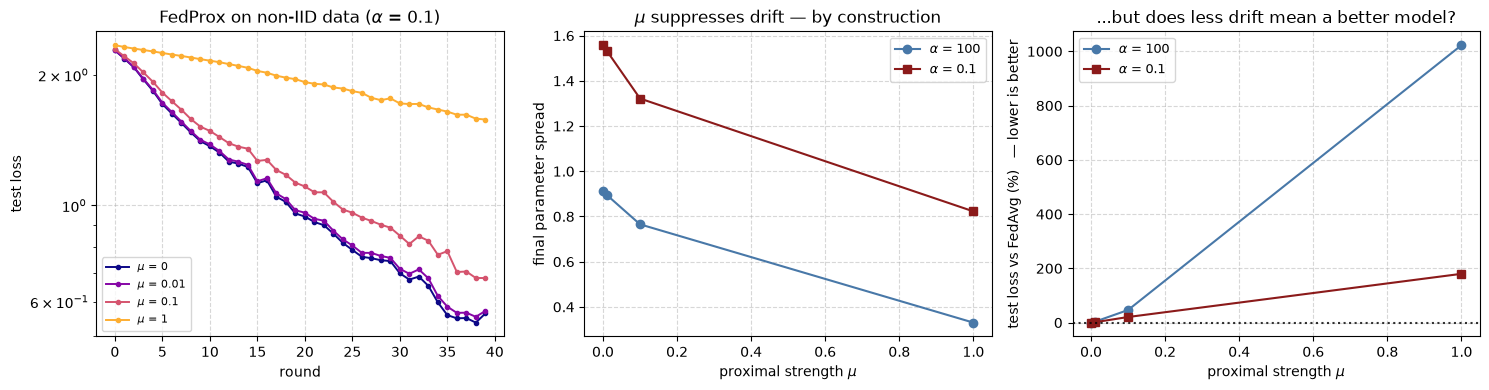

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.0))
mu_cols = plt.cm.plasma(np.linspace(0, 0.82, len(MUS)))

for c, mu in zip(mu_cols, MUS):
    h = prox_runs[(ALPHA_NID, mu)]
    ax[0].semilogy([d["rnd"] for d in h], [d["loss"] for d in h], "o-", color=c, ms=3, lw=1.4,
                   label=f"$\\mu$ = {mu:g}")
ax[0].set_xlabel("round"); ax[0].set_ylabel("test loss")
ax[0].set_title(f"FedProx on non-IID data ($\\alpha$ = {ALPHA_NID:g})")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5)

for a, mk, c in [(ALPHA_IID, "o-", "#4878a8"), (ALPHA_NID, "s-", "#8b1a1a")]:
    ax[1].plot(MUS, [prox_runs[(a, m)][-1]["spread"] for m in MUS], mk, color=c,
               label=f"$\\alpha$ = {a:g}")
ax[1].set_xlabel(r"proximal strength $\mu$"); ax[1].set_ylabel("final parameter spread")
ax[1].set_title(r"$\mu$ suppresses drift — by construction")
ax[1].legend(fontsize=9); ax[1].grid(True, ls="--", alpha=0.5)

for a, mk, c in [(ALPHA_IID, "o-", "#4878a8"), (ALPHA_NID, "s-", "#8b1a1a")]:
    base = prox_runs[(a, 0.0)][-1]["loss"]
    ax[2].plot(MUS, [100 * (prox_runs[(a, m)][-1]["loss"] / base - 1) for m in MUS], mk,
               color=c, label=f"$\\alpha$ = {a:g}")
ax[2].axhline(0, color="k", ls=":", alpha=0.8)
ax[2].set_xlabel(r"proximal strength $\mu$")
ax[2].set_ylabel("test loss vs FedAvg (%)   — lower is better")
ax[2].set_title("...but does less drift mean a better model?")
ax[2].legend(fontsize=9); ax[2].grid(True, ls="--", alpha=0.5)

plt.tight_layout()

for a, name in [(ALPHA_IID, "IID"), (ALPHA_NID, "non-IID")]:
    s0 = prox_runs[(a, 0.0)][-1]["spread"]; s1 = prox_runs[(a, MUS[-1])][-1]["spread"]
    l0 = prox_runs[(a, 0.0)][-1]["loss"]; l1 = prox_runs[(a, MUS[-1])][-1]["loss"]
    print(f"{name:>8}: mu 0 -> {MUS[-1]:g} cut drift by {100 * (1 - s1 / s0):>4.0f}% "
          f"and changed test loss by {100 * (l1 / l0 - 1):>+5.1f}%")

> **Observe:** FedProx reduces client movement here, but less movement does not mean better
> learning.
>
> In this experiment, every tested $\mu > 0$ produces higher test loss than $\mu = 0$, on both
> IID and non-IID data. FedAvg has the lowest loss.
>
> Possible reasons:
>
> - The penalty slows progress within our 40-round budget; a longer run might change the
>   result. Exercise 2 tests this on the quadratic.
> - Every client performs the same 16 steps, so the unequal-work setting FedProx's theory
>   targets never occurs.
> - This is a small experiment: 6 clients, a tiny model, and synthetic data.
>
> These are possible explanations, not proven causes.
>
> On the quadratic example ($\mu = 1$, $\tau = 20$), FedProx reduces bias from $1.06$ to
> $0.61$, but does not remove it. It restrains local movement; SCAFFOLD instead corrects
> local update directions.


### 🔬 Exercise 2

**Exercise: find the regime where FedProx wins.** The Observe cell claims FedProx did not
help *because we measured in the wrong regime*, and names the regime it expects to win in:
**converged, drift-limited, large $\tau$**. Do not take that on faith — it is exactly the
kind of excuse a null result attracts. Test it where the answer is unambiguous.

On Section 1's quadratic (deterministic gradients, no minibatch noise, full participation, so
drift is *purely* bias):

1. First work out the **stability ceiling**: the penalized objective has curvature
   $H_k + \mu I$, so gradient descent needs $\eta(\lambda_{\max}(H_k) + \mu) < 2$. With
   $\eta = 0.1$ and $\lambda_{\max} = 4$, what is the largest usable $\mu$?
2. Sweep $\mu$ up to that ceiling at $\tau \in \{2, 10, 50\}$, running to convergence, and
   report the final bias $\lVert w^\infty - \theta^\star\rVert$. For each $\tau$, which $\mu$
   is best? Is it interior, and does it move with $\tau$?
3. Now measure the brake: report **rounds to reach a bias of 0.3** at $\tau = 50$ for each
   $\mu$. What does $\mu$ cost you?
4. Does any $\mu$ drive the bias to **zero**? Explain from Section 1's fixed-point equation.


In [25]:
# --- Reference solution (instructor: blank this out for students) ---

# (1) the stability ceiling
L_MAX = max(np.linalg.eigvalsh(H).max() for H in Hs)
MU_CEIL = 2.0 / ETA_Q - L_MAX
print(f"(1) lambda_max(H_k) = {L_MAX:g}, eta = {ETA_Q}")
print(f"    stability needs eta*(lambda_max + mu) < 2  ->  mu < {MU_CEIL:g}")
print(f"    So mu is NOT a free dial: at this eta it lives in [0, {MU_CEIL:g}).\n")

# (2) sweep, to convergence
mus_x = [0.0, 0.5, 2.0, 5.0, 9.0, 15.0]
taus_x = [2, 10, 50]
print("(2) final bias ||w_inf - theta*|| after 3000 rounds (converged)")
print(f"{'tau':>5}  " + "".join(f"{'mu=' + f'{m:g}':>11}" for m in mus_x) + f"{'best mu':>10}")
print("-" * 82)
for tau in taus_x:
    row, biases = "", []
    for mu in mus_x:
        b = np.linalg.norm(fedavg_quadratic(3000, tau, ETA_Q, mu=mu)[-1] - w_star)
        biases.append(b)
        row += f"{b:>11.5f}" if np.isfinite(b) else f"{'DIVERGED':>11}"
    best = mus_x[int(np.argmin(biases))]
    print(f"{tau:>5}  {row}{best:>10g}")

print("\n    The best mu MOVES WITH tau. At tau=2 there is almost no bias to fix, so the")
print("    brake is pure cost and mu=0 wins. At tau=10 the best mu is interior. At tau=50 the")
print("    bias dominates and mu wants to go as high as stability allows. There is no safe")
print("    default: mu must be tuned per problem, per tau, and per eta.")

# (3) the brake, measured
TARGET = 0.3
print(f"\n(3) rounds to reach bias <= {TARGET} at tau = 50:")
print(f"{'mu':>8}  {'rounds to target':>17}  {'final bias':>11}")
print("-" * 41)
for mu in mus_x:
    tr = fedavg_quadratic(3000, 50, ETA_Q, mu=mu)
    d = np.linalg.norm(tr - w_star, axis=1)
    hit = np.where(d <= TARGET)[0]
    print(f"{mu:>8g}  {(str(int(hit[0])) if len(hit) else 'never'):>17}  {d[-1]:>11.5f}")
print("    ^ two opposite effects in one column. Small mu NEVER reaches the target (the")
print("      bias floor is above it). Large mu reaches it -- but LATER as mu grows")
print("      (mu=5 at round 11, mu=15 at round 19). That is the brake, in units of rounds:")
print("      FedProx trades early speed for a better endpoint. On a short round budget")
print("      (like Section 5's 40) you pay the brake and never collect the endpoint.")

# (4) can mu ever reach zero bias?
print(f"\n(4) can any mu drive the bias to ZERO?")
for mu in [9.0, 15.0, 15.9]:
    b = np.linalg.norm(fedavg_quadratic(5000, 50, ETA_Q, mu=mu)[-1] - w_star)
    print(f"    mu = {mu:>5g} (eta*(L+mu) = {ETA_Q * (L_MAX + mu):.2f}) -> bias {b:.6f}")
with np.errstate(over="ignore", invalid="ignore"):     # we EXPECT this one to blow up
    b_div = np.linalg.norm(fedavg_quadratic(200, 50, ETA_Q, mu=25.0)[-1] - w_star)
print(f"    mu = {25.0:>5g} (eta*(L+mu) = {ETA_Q * (L_MAX + 25.0):.2f}) -> bias "
      f"{'DIVERGED' if not np.isfinite(b_div) or b_div > 1e6 else f'{b_div:.6f}'}  <- past the ceiling")
print("    ^ note mu = 15.9: right at the ceiling the bias RISES again. Near eta*(L+mu) = 2")
print("      the local steps oscillate, which reweights the clients badly.")
print("\n    No -- for two independent reasons, and both are structural.")
print("    (a) The fixed point. FedProx's local map is still  I - (I - eta(H_k + mu I))^tau")
print("        applied to a shifted target, so the M_k are STILL client-dependent and STILL")
print("        non-proportional. The fixed point still solves the wrong system in Section 1's")
print("        sense -- just a less wrong one. The bias shrinks; it does not vanish.")
print("    (b) The ceiling. Even the limit is unreachable: mu is capped by stability, and")
print("        past the cap the method diverges rather than freezing.")
print("    FedProx SHRINKS the bias. It cannot DELETE it. Section 6 can.")

(1) lambda_max(H_k) = 4, eta = 0.1
    stability needs eta*(lambda_max + mu) < 2  ->  mu < 16
    So mu is NOT a free dial: at this eta it lives in [0, 16).

(2) final bias ||w_inf - theta*|| after 3000 rounds (converged)
  tau         mu=0     mu=0.5       mu=2       mu=5       mu=9      mu=15   best mu
----------------------------------------------------------------------------------
    2      0.06023    0.06214    0.06870    0.08706    0.13529    0.80034         0


   10      0.58756    0.51900    0.34992    0.17833    0.10315    0.22498         9


   50      1.68973    0.98746    0.39541    0.17857    0.10315    0.06478        15

    The best mu MOVES WITH tau. At tau=2 there is almost no bias to fix, so the
    brake is pure cost and mu=0 wins. At tau=10 the best mu is interior. At tau=50 the
    bias dominates and mu wants to go as high as stability allows. There is no safe
    default: mu must be tuned per problem, per tau, and per eta.

(3) rounds to reach bias <= 0.3 at tau = 50:
      mu   rounds to target   final bias
-----------------------------------------


       0              never      1.68973


     0.5              never      0.98746


       2              never      0.39541


... (2 outputs left out)

      15                 19      0.06478
    ^ two opposite effects in one column. Small mu NEVER reaches the target (the
      bias floor is above it). Large mu reaches it -- but LATER as mu grows
      (mu=5 at round 11, mu=15 at round 19). That is the brake, in units of rounds:
      FedProx trades early speed for a better endpoint. On a short round budget
      (like Section 5's 40) you pay the brake and never collect the endpoint.

(4) can any mu drive the bias to ZERO?


    mu =     9 (eta*(L+mu) = 1.30) -> bias 0.103150


    mu =    15 (eta*(L+mu) = 1.90) -> bias 0.064778


    mu =  15.9 (eta*(L+mu) = 1.99) -> bias 0.490938
    mu =    25 (eta*(L+mu) = 2.90) -> bias DIVERGED  <- past the ceiling
    ^ note mu = 15.9: right at the ceiling the bias RISES again. Near eta*(L+mu) = 2
      the local steps oscillate, which reweights the clients badly.

    No -- for two independent reasons, and both are structural.
    (a) The fixed point. FedProx's local map is still  I - (I - eta(H_k + mu I))^tau
        applied to a shifted target, so the M_k are STILL client-dependent and STILL
        non-proportional. The fixed point still solves the wrong system in Section 1's
        sense -- just a less wrong one. The bias shrinks; it does not vanish.
    (b) The ceiling. Even the limit is unreachable: mu is capped by stability, and
        past the cap the method diverges rather than freezing.
    FedProx SHRINKS the bias. It cannot DELETE it. Section 6 can.


---

## 6. SCAFFOLD: correcting the direction, not the distance

**SCAFFOLD** (Karimireddy et al., 2020) starts from what Exercise 2 showed: the problem is not
that clients move **too far**, but that they move in the **wrong direction**. Client $k$
follows $\nabla F_k$, while we want $\nabla F$. The error is

$$\nabla F_k(\theta) - \nabla F(\theta).$$

A client cannot compute this, because it does not have $F$. But it can **estimate** it and
reuse the estimate in the next round. This is a **control variate**, a standard
variance-reduction tool, applied across clients.

Each client keeps $c_k \approx \nabla F_k$, and the server keeps
$c \approx \nabla F = \frac{1}{K}\sum_k c_k$. The local step becomes

$$y_k \leftarrow y_k - \eta\Big(\underbrace{g_k(y_k)}_{\text{client gradient}}
\;\underbrace{-\; c_k \;+\; c}_{\text{drift correction}}\Big)$$

If the estimates are exact, then at $y_k = \theta^{(r)}$:
$g_k - c_k + c \approx \nabla F_k - \nabla F_k + \nabla F = \nabla F$.
**Each client follows the global gradient while computing only its own.** All clients now
descend the same function, so there is no drift.

After the local steps, each client updates its control variate (Option II in the paper,
which needs no extra gradient computation):

$$c_k^{+} = c_k - c + \frac{1}{\tau\eta}\big(\theta^{(r)} - y_k\big)$$

Clients send both $\Delta y_k = y_k - \theta^{(r)}$ and $\Delta c_k = c_k^+ - c_k$ to the
server, which updates

$$\theta^{(r+1)} = \theta^{(r)} + \frac{\eta_g}{|S|}\sum_{k \in S}\Delta y_k, \qquad
c \leftarrow c + \frac{1}{K}\sum_{k \in S}\Delta c_k.$$

**The cost.** $c_k$ is as large as the model, so:

- **Uplink doubles:** clients send $\Delta y_k$ and $\Delta c_k$.
- **Downlink doubles:** the server sends $\theta^{(r)}$ and $c$.
- **Clients must keep state:** $c_k$ has to persist between rounds.

The last point is the biggest obstacle in cross-device FL. A client may participate only
once in a thousand rounds; by then its $c_k$ describes a model that no longer exists.
Exercise 3 tests this.

We first test SCAFFOLD on Section 1's quadratic, where we know $\theta^\star$ exactly and can
measure bias directly.


In [26]:
def scaffold_quadratic(rounds, tau, eta, eta_g=1.0, participation=1.0, seed=0,
                       stateless=False):
    # SCAFFOLD with Option-II control variates, on Section 1's quadratics.
    # stateless=True: every client starts each round with c_k = 0 -- it keeps no memory,
    # like a cross-device client seen for the first time (Exercise 3).
    r_sel = np.random.default_rng(seed)
    w = np.zeros(2)
    c = np.zeros(2)                       # server control variate  ~ grad F
    cis = np.zeros((K_Q, 2))              # client control variates ~ grad F_k  <- STATEFUL
    traj = [w.copy()]
    for r in range(rounds):
        n_sel = max(1, int(round(participation * K_Q)))
        S = r_sel.choice(K_Q, size=n_sel, replace=False) if participation < 1.0 else np.arange(K_Q)
        dys, dcs = [], []
        for k in S:
            ck = np.zeros(2) if stateless else cis[k]
            y = w.copy()
            for t in range(tau):
                y = y - eta * (grad_k(k, y) - ck + c)          # <- the ONE changed line
            ci_new = ck - c + (w - y) / (tau * eta)            # Option II refresh
            dys.append(y - w)
            dcs.append(ci_new - ck)
            if not stateless:
                cis[k] = ci_new                                # client REMEMBERS
        w = w + eta_g * np.mean(np.array(dys), axis=0)
        c = c + np.sum(np.array(dcs), axis=0) / K_Q            # note: / K, not / |S|
        traj.append(w.copy())
    return np.array(traj)


print(f"Section 1's quadratics: K={K_Q} clients, exact gradients, full participation.")
print("Every federated constraint EXCEPT non-IID is switched off, so any bias is drift.\n")
print(f"{'tau':>5}  {'FedAvg bias':>12}  {'FedProx(mu=1)':>14}  {'FedProx(mu=10)':>15}  "
      f"{'SCAFFOLD bias':>14}")
print("-" * 68)
scaf_rows = []
for tau in [1, 2, 5, 10, 20, 50]:
    ba = np.linalg.norm(fedavg_quadratic(2000, tau, ETA_Q)[-1] - w_star)
    p1 = np.linalg.norm(fedavg_quadratic(2000, tau, ETA_Q, mu=1.0)[-1] - w_star)
    p10 = np.linalg.norm(fedavg_quadratic(2000, tau, ETA_Q, mu=10.0)[-1] - w_star)
    bs = np.linalg.norm(scaffold_quadratic(2000, tau, ETA_Q)[-1] - w_star)
    scaf_rows.append((tau, ba, p1, p10, bs))
    print(f"{tau:>5}  {ba:>12.6f}  {p1:>14.6f}  {p10:>15.6f}  {bs:>14.3e}")

print("\nRead the last column: SCAFFOLD's bias is ZERO -- machine precision -- at EVERY tau.")
print("Not smaller. Zero. And read the FedProx columns against it: mu=10 gets the bias down")
print("to ~0.1 at tau=50 and STOPS there, no matter how long you run.")
print("\nThat is the difference between correcting a DIRECTION and shortening a DISTANCE.")

Section 1's quadratics: K=3 clients, exact gradients, full participation.
Every federated constraint EXCEPT non-IID is switched off, so any bias is drift.

  tau   FedAvg bias   FedProx(mu=1)   FedProx(mu=10)   SCAFFOLD bias
--------------------------------------------------------------------
    1      0.000000        0.000000         0.000000       0.000e+00


    2      0.060225        0.064182         0.157041       0.000e+00


    5      0.260591        0.248636         0.089839       0.000e+00

   10      0.587560        0.455831         0.093334       0.000e+00


   20      1.061171        0.611450         0.093298       1.110e-16


   50      1.689730        0.663336         0.093298       2.220e-16

Read the last column: SCAFFOLD's bias is ZERO -- machine precision -- at EVERY tau.
Not smaller. Zero. And read the FedProx columns against it: mu=10 gets the bias down
to ~0.1 at tau=50 and STOPS there, no matter how long you run.

That is the difference between correcting a DIRECTION and shortening a DISTANCE.


The right panel is the whole section. FedAvg drops fast and FLATTENS -- that plateau
is not slow convergence, it is CONVERGENCE, to the wrong point. FedProx flattens
lower and later (a brake helps, a little, and costs early speed). SCAFFOLD keeps
going down to 1e-16, because there is no floor: it is solving the right problem.


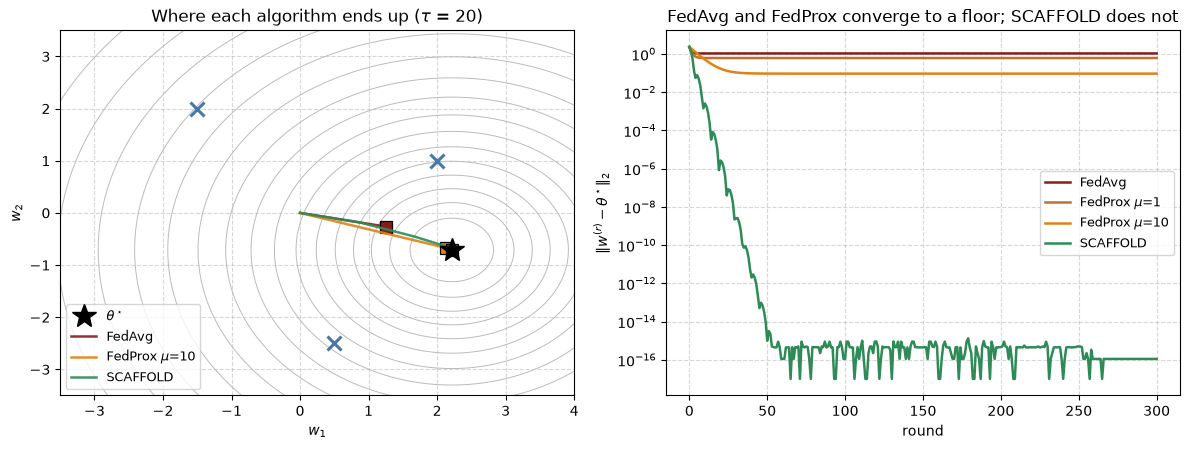

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

# ---- left: trajectories on the contours, tau = 20 ----
ax[0].contour(gx, gy, Z, levels=np.geomspace(Z.min() + 1e-3, Z.max(), 18),
              colors="#bbbbbb", linewidths=0.7)
for k in range(K_Q):
    ax[0].plot(*wks[k], "x", color="#4878a8", ms=10, mew=2.2)
ax[0].plot(*w_star, "*", color="k", ms=18, zorder=6, label=r"$\theta^\star$")

TAU_S = 20
for name, tr, c in [
        ("FedAvg", fedavg_quadratic(120, TAU_S, ETA_Q), "#8b1a1a"),
        (r"FedProx $\mu$=10", fedavg_quadratic(120, TAU_S, ETA_Q, mu=10.0), "#e08214"),
        ("SCAFFOLD", scaffold_quadratic(120, TAU_S, ETA_Q), "#2e8b57")]:
    ax[0].plot(tr[:, 0], tr[:, 1], "-", color=c, lw=1.8, alpha=0.9, label=name)
    ax[0].plot(*tr[-1], "s", color=c, ms=8, mec="k", mew=0.9)
ax[0].set_xlabel("$w_1$"); ax[0].set_ylabel("$w_2$")
ax[0].set_title(f"Where each algorithm ends up ($\\tau$ = {TAU_S})")
ax[0].legend(fontsize=9, loc="lower left"); ax[0].grid(True, ls="--", alpha=0.5)

# ---- right: distance to theta* vs round ----
for name, tr, c in [
        ("FedAvg", fedavg_quadratic(300, TAU_S, ETA_Q), "#8b1a1a"),
        (r"FedProx $\mu$=1", fedavg_quadratic(300, TAU_S, ETA_Q, mu=1.0), "#c07030"),
        (r"FedProx $\mu$=10", fedavg_quadratic(300, TAU_S, ETA_Q, mu=10.0), "#e08214"),
        ("SCAFFOLD", scaffold_quadratic(300, TAU_S, ETA_Q), "#2e8b57")]:
    ax[1].semilogy(np.maximum(np.linalg.norm(tr - w_star, axis=1), 1e-17), "-", color=c,
                   lw=1.8, label=name)
ax[1].set_xlabel("round"); ax[1].set_ylabel(r"$\|w^{(r)} - \theta^\star\|_2$")
ax[1].set_title(r"FedAvg and FedProx converge to a floor; SCAFFOLD does not")
ax[1].legend(fontsize=9); ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

print("The right panel is the whole section. FedAvg drops fast and FLATTENS -- that plateau")
print("is not slow convergence, it is CONVERGENCE, to the wrong point. FedProx flattens")
print("lower and later (a brake helps, a little, and costs early speed). SCAFFOLD keeps")
print("going down to 1e-16, because there is no floor: it is solving the right problem.")

> **Observe:** SCAFFOLD's bias is zero to machine precision at every $\tau$, including
> $\tau = 50$. On this problem it removes the link between $\tau$ and the endpoint: more
> local steps no longer change where training converges.
>
> The right panel shows the difference. FedAvg drops quickly and then stays flat — that
> plateau is convergence to the wrong point, not slow progress. FedProx flattens lower and
> later. SCAFFOLD keeps decreasing because it converges to $\theta^\star$.
>
> This is SCAFFOLD's best case: convex, exact gradients, three clients, all participating
> every round, and control variates refreshed every round. It shows the *mechanism*, not
> that SCAFFOLD is practical. The table below lists the costs, and Exercise 3 removes two of
> these assumptions: full participation and client memory.


### Comparing FedAvg, FedProx, and SCAFFOLD

| | **FedAvg** | **FedProx** | **SCAFFOLD** |
|---|---|---|---|
| **Main idea** | Average local models | Penalize movement from the server model | Correct local update directions |
| **Drift control** | None | Acts as a brake | Uses control variates |
| **Extra persistent client state** | None | None | One model-sized vector |
| **Communication relative to FedAvg** | 1× | 1× | About 2× |
| **Added tuning** | — | Penalty strength $\mu$ | Server learning rate $\eta_g$ |
| **Bias in our quadratic, $\tau = 50$** | $1.69$ | $0.09$ at $\mu = 10$ | Approximately zero |

These bias values describe this experiment, not guarantees for every problem. SCAFFOLD's
theory avoids the client-dissimilarity dependence found in standard FedAvg bounds, but its
practical benefit still depends on the setting.

The main trade-off is drift correction versus communication and memory:

- **Cross-silo FL:** stable participants, such as hospitals, can retain correction vectors.
  SCAFFOLD is easier to deploy here.
- **Cross-device FL:** phones participate infrequently and may lose local state. Persistent
  corrections and doubled communication make SCAFFOLD harder to deploy.

**Remember:** FedAvg is the baseline, FedProx restrains local movement, and SCAFFOLD corrects
its direction—at an additional systems cost.


### 🔬 Exercise 3

**Exercise: stress SCAFFOLD's assumptions.** The table says SCAFFOLD works poorly in
cross-device FL. Measure what actually breaks, on the quadratic at $\tau = 20$.

1. **Partial participation.** Sweep participation $C \in \{1.0, 0.67, 0.33\}$ for FedAvg and
   SCAFFOLD. Report the final distance to $\theta^\star$ (for FedAvg, average over the last
   200 rounds — under partial participation it does not settle on one point) and the number
   of rounds SCAFFOLD needs to reach $10^{-8}$.
2. Do stale control variates break SCAFFOLD's exactness, or only slow it down? Explain from
   the update rule: what does a stale $c_k$ estimate, and what happens to that estimate once
   $\theta$ stops moving?
3. **No client memory.** Rerun with `stateless=True`, so every client starts each round with
   $c_k = 0$ — like a cross-device client seen for the first time. What does SCAFFOLD reduce
   to?
4. Account for the communication: how many **bytes per client per round** do FedAvg and
   SCAFFOLD move for our small model? When would SCAFFOLD's doubling be worth it?


In [28]:
# --- Reference solution (instructor: blank this out for students) ---

def fedavg_partial(rounds, tau, eta, C, seed=0):
    # FedAvg with the same client sampling as scaffold_quadratic, for a fair comparison.
    rs = np.random.default_rng(seed)
    w = np.zeros(2)
    traj = [w.copy()]
    for r in range(rounds):
        n_sel = max(1, int(round(C * K_Q)))
        S = rs.choice(K_Q, size=n_sel, replace=False) if C < 1.0 else np.arange(K_Q)
        ys = []
        for k in S:
            y = w.copy()
            for t in range(tau):
                y = y - eta * grad_k(k, y)
            ys.append(y)
        w = np.mean(np.array(ys), axis=0)
        traj.append(w.copy())
    return np.array(traj)


def first_hit(d, target):
    hit = np.where(d <= target)[0]
    return str(int(hit[0])) if len(hit) else "never"


PARTS_C = [1.0, 0.67, 0.33]
fa_dist = {C: np.linalg.norm(fedavg_partial(2000, 20, ETA_Q, C) - w_star, axis=1) for C in PARTS_C}

print("(1) distance to theta* after 2000 rounds, tau = 20\n")
print(f"{'participation':>14}  {'clients/round':>14}  {'FedAvg (mean, last 200)':>24}  "
      f"{'SCAFFOLD final':>15}  {'SCAFFOLD rounds to 1e-8':>24}")
print("-" * 99)
for C in PARTS_C:
    ds = np.linalg.norm(scaffold_quadratic(2000, 20, ETA_Q, participation=C) - w_star, axis=1)
    print(f"{C:>14.2f}  {max(1, int(round(C * K_Q))):>14}  {fa_dist[C][-200:].mean():>24.4f}  "
          f"{ds[-1]:>15.1e}  {first_hit(ds, 1e-8):>24}")

print("\n(2) Staleness SLOWS SCAFFOLD but does not break its exactness here: it still reaches")
print("    theta* to machine precision, just in more rounds. c_k estimates grad F_k at the")
print("    model where client k last trained. While theta is moving that estimate is out of")
print("    date and the correction is off; once theta stops moving, old and current")
print("    gradients coincide and the fixed point is exact again. With stochastic gradients")
print("    staleness would also add error -- not tested here. FedAvg, meanwhile, never")
print("    settles under partial participation: each round follows whichever clients were")
print("    sampled.")

print("\n(3) stateless clients (c_k = 0 at every participation), tau = 20, mean of last 200 rounds")
print(f"{'participation':>14}  {'FedAvg':>10}  {'SCAFFOLD, no memory':>20}")
print("-" * 50)
for C in PARTS_C:
    d0 = np.linalg.norm(scaffold_quadratic(2000, 20, ETA_Q, participation=C, stateless=True)
                        - w_star, axis=1)
    print(f"{C:>14.2f}  {fa_dist[C][-200:].mean():>10.4f}  {d0[-200:].mean():>20.4f}")
print("    ^ without memory SCAFFOLD loses its correction: at full participation it lands")
print("      exactly where FedAvg does, and it is no better under partial participation.")
print("      This is the real cross-device problem -- a client seen once has no c_k.")
print()
# (4) communication accounting
BYTES = N_PARAMS * 4
print(f"(4) model = {N_PARAMS:,} params = {BYTES:,} bytes at float32\n")
print(f"{'algorithm':>12}  {'downlink':>10}  {'uplink':>10}  {'per client/round':>17}  {'vs FedAvg':>10}")
print("-" * 66)
for name, mult in [("FedAvg", 1), ("FedProx", 1), ("SCAFFOLD", 2)]:
    tot = 2 * mult * BYTES
    print(f"{name:>12}  {mult * BYTES:>9,}B  {mult * BYTES:>9,}B  {tot:>16,}B  {mult:>9.1f}x")
print("\n    SCAFFOLD doubles BOTH directions, and on a phone the UPLINK is the scarce one")
print("    (Week 7: 5 Mb/s up). So the question is not 'is SCAFFOLD better' but 'is it more")
print("    than 2x better than spending those same bytes on 2x more ROUNDS of FedAvg?'")
print("    On our quadratic, yes -- trivially: FedAvg's bias is a floor that no number of")
print("    rounds removes. On a real cross-device deployment, usually no. Week 10 makes")
print("    this trade quantitative by putting accuracy on a bytes axis.")

(1) distance to theta* after 2000 rounds, tau = 20

 participation   clients/round   FedAvg (mean, last 200)   SCAFFOLD final   SCAFFOLD rounds to 1e-8
---------------------------------------------------------------------------------------------------
          1.00               3                    1.0612          1.1e-16                        29


          0.67               2                    1.1752          4.4e-16                       196
          0.33               1                    1.6840          1.1e-16                       415

(2) Staleness SLOWS SCAFFOLD but does not break its exactness here: it still reaches
    theta* to machine precision, just in more rounds. c_k estimates grad F_k at the
    model where client k last trained. While theta is moving that estimate is out of
    date and the correction is off; once theta stops moving, old and current
    gradients coincide and the fixed point is exact again. With stochastic gradients
    staleness would also add error -- not tested here. FedAvg, meanwhile, never
    settles under partial participation: each round follows whichever clients were
    sampled.

(3) stateless clients (c_k = 0 at every participation), tau = 20, mean of last 200 rounds
 participation      FedAvg   SCAFFOLD, no memory
--------------------------------------------------


          1.00      1.0612                1.0612
          0.67      1.1752                1.2463
          0.33      1.6840                1.8378
    ^ without memory SCAFFOLD loses its correction: at full participation it lands
      exactly where FedAvg does, and it is no better under partial participation.
      This is the real cross-device problem -- a client seen once has no c_k.

(4) model = 914 params = 3,656 bytes at float32

   algorithm    downlink      uplink   per client/round   vs FedAvg
------------------------------------------------------------------
      FedAvg      3,656B      3,656B             7,312B        1.0x
     FedProx      3,656B      3,656B             7,312B        1.0x
    SCAFFOLD      7,312B      7,312B            14,624B        2.0x

    SCAFFOLD doubles BOTH directions, and on a phone the UPLINK is the scarce one
    (Week 7: 5 Mb/s up). So the question is not 'is SCAFFOLD better' but 'is it more
    than 2x better than spending those same bytes on 

---

## 7. Consensus optimization and the graph Laplacian

Without a server, clients exchange models with their neighbours. The goal is still to
minimize the global loss while making all clients agree.

For an undirected graph, the **graph Laplacian** is

$$L = D - A,$$

where $D$ contains neighbour counts and $A$ records connections. Its key property is

$$x^\top L x = \sum_{(i,j) \in E} (x_i - x_j)^2.$$

This measures **disagreement between neighbours**. On a connected graph, zero disagreement
means everyone agrees.

Clients move toward agreement using

$$x^{(t+1)} = \underbrace{(I - \alpha L)}_{W}\, x^{(t)}.$$

$W$ is the **mixing matrix**. This update preserves the average and gradually removes
differences—provided the mixing step $\alpha$ is small enough.

Two eigenvalues determine the speed:

- $\lambda_2$: how well the graph connects everyone.
- $\lambda_K$: how large a mixing step remains stable.

Choosing $\alpha = 1/\lambda_K$ gives the disagreement contraction factor

$$\rho(W) = 1 - \frac{\lambda_2}{\lambda_K}.$$

Smaller $\rho(W)$ means faster agreement. So compare the ratio $\lambda_2/\lambda_K$, not just
$\lambda_2$. A graph may connect clients well but still require small steps—exactly what we
will see with the star graph.


In [29]:
def ring_graph(n):
    A = np.zeros((n, n))
    for i in range(n):
        A[i, (i + 1) % n] = A[(i + 1) % n, i] = 1.0
    return A

def star_graph(n):
    A = np.zeros((n, n)); A[0, 1:] = 1.0; A[1:, 0] = 1.0
    return A

def complete_graph(n):
    return np.ones((n, n)) - np.eye(n)

def grid_graph(rows, cols):
    n = rows * cols
    A = np.zeros((n, n))
    for i in range(rows):
        for j in range(cols):
            u = i * cols + j
            for di, dj in [(0, 1), (1, 0)]:
                a, b = i + di, j + dj
                if a < rows and b < cols:
                    v = a * cols + b
                    A[u, v] = A[v, u] = 1.0
    return A

def er_graph(n, p=0.35, seed=0):
    r = np.random.default_rng(seed)
    while True:
        A = (r.random((n, n)) < p).astype(float)
        A = np.triu(A, 1); A = A + A.T
        if np.sort(np.linalg.eigvalsh(np.diag(A.sum(1)) - A))[1] > 1e-8:   # connected?
            return A

def laplacian(A):
    return np.diag(A.sum(1)) - A


In [30]:
N_NODES = 12
GRAPHS = {"ring": ring_graph(N_NODES), "star": star_graph(N_NODES),
          "2D grid (3x4)": grid_graph(3, 4), "random ER(p=0.35)": er_graph(N_NODES),
          "complete": complete_graph(N_NODES)}

# The quadratic form IS the disagreement -- check it rather than believe it.
A_r = GRAPHS["ring"]; L_r = laplacian(A_r)
x_t = np.random.default_rng(1).normal(size=N_NODES)
edges = [(i, j) for i in range(N_NODES) for j in range(i + 1, N_NODES) if A_r[i, j] > 0]
by_hand = sum((x_t[i] - x_t[j]) ** 2 for i, j in edges)
print(f"x^T L x = {x_t @ L_r @ x_t:.6f}")
print(f"sum over edges of (x_i - x_j)^2 = {by_hand:.6f}")
print(f"identical: {np.isclose(x_t @ L_r @ x_t, by_hand)}   <- L measures DISAGREEMENT\n")

print(f"{'graph':>19}  {'edges':>6}  {'lambda_2':>9}  {'lambda_K':>9}  {'gap ratio':>10}  "
      f"{'rho(W)':>8}")
print("-" * 70)
G_STATS = {}
for name, A in GRAPHS.items():
    L = laplacian(A)
    ev = np.sort(np.linalg.eigvalsh(L))
    lam2, lamK = ev[1], ev[-1]
    W = np.eye(N_NODES) - L / lamK                  # alpha = 1 / lambda_K
    evW = np.sort(np.linalg.eigvalsh(W))
    rho = max(abs(evW[0]), abs(evW[-2]))            # ignore the eigenvalue exactly at 1
    G_STATS[name] = dict(lam2=lam2, lamK=lamK, rho=rho, W=W, edges=int(A.sum() // 2))
    print(f"{name:>19}  {int(A.sum() // 2):>6}  {lam2:>9.4f}  {lamK:>9.4f}  "
          f"{lam2 / lamK:>10.4f}  {rho:>8.4f}")
print(f"\nrho(W) = 1 - lambda_2/lambda_K exactly, by construction. Check the complete graph:")
print(f"   lambda_2 = lambda_K = {N_NODES} -> rho = 0 -> consensus in ONE step. That is an AllReduce.")

x^T L x = 10.873242
sum over edges of (x_i - x_j)^2 = 10.873242
identical: True   <- L measures DISAGREEMENT

              graph   edges   lambda_2   lambda_K   gap ratio    rho(W)
----------------------------------------------------------------------
               ring      12     0.2679     4.0000      0.0670    0.9330
               star      11     1.0000    12.0000      0.0833    0.9167
      2D grid (3x4)      17     0.5858     6.4142      0.0913    0.9087
  random ER(p=0.35)      22     1.3814     7.3233      0.1886    0.8114
           complete      66    12.0000    12.0000      1.0000    0.0000

rho(W) = 1 - lambda_2/lambda_K exactly, by construction. Check the complete graph:
   lambda_2 = lambda_K = 12 -> rho = 0 -> consensus in ONE step. That is an AllReduce.


In [31]:
# ---- Run the actual averaging and see whether rho predicts it ----
x0 = np.random.default_rng(0).normal(size=N_NODES) * 3.0
mean0 = x0.mean()

def consensus_run(W, x0, steps=400):
    x, errs = x0.copy(), []
    for _ in range(steps):
        errs.append(np.linalg.norm(x - mean0))
        x = W @ x
    return np.array(errs), x

print(f"average consensus from a random x0 (mean = {mean0:.4f}) on {N_NODES} nodes")
print(f"{'graph':>19}  {'rho(W)':>8}  {'iters to 1e-6':>14}  {'predicted':>10}  "
      f"{'mean drift':>12}")
print("-" * 72)
CONS = {}
for name, st in G_STATS.items():
    errs, xf = consensus_run(st["W"], x0)
    CONS[name] = errs
    rel = errs / errs[0]
    hit = np.where(rel <= 1e-6)[0]
    it = int(hit[0]) if len(hit) else -1
    pred = int(np.ceil(np.log(1e-6) / np.log(st["rho"]))) if st["rho"] > 0 else 1
    print(f"{name:>19}  {st['rho']:>8.4f}  {str(it) if it > 0 else '>400':>14}  {pred:>10}  "
          f"{abs(xf.mean() - mean0):>12.2e}")

print("\nTwo things just happened, and both are the point.")
print("  1. log(1e-6)/log(rho) predicts the iteration count from the spectrum alone: it")
print("     matches the ring and star almost exactly and is an upper bound for the others")
print("     (this start vector puts less weight on their slowest mode). Not a curve fit.")
print("  2. The 'mean drift' column is ~1e-15 everywhere: every W preserves the mean")
print("     exactly, because W1 = 1. That is why this is averaging and not just smoothing,")
print("     and it is the decentralized analogue of FedAvg's weights summing to one.")

average consensus from a random x0 (mean = 0.0662) on 12 nodes
              graph    rho(W)   iters to 1e-6   predicted    mean drift
------------------------------------------------------------------------
               ring    0.9330             189         200      2.50e-16
               star    0.9167             159         159      9.71e-16
      2D grid (3x4)    0.9087             137         145      6.94e-17
  random ER(p=0.35)    0.8114              53          67      3.33e-16
           complete    0.0000               1           1      2.78e-17

Two things just happened, and both are the point.
  1. log(1e-6)/log(rho) predicts the iteration count from the spectrum alone: it
     matches the ring and star almost exactly and is an upper bound for the others
     (this start vector puts less weight on their slowest mode). Not a curve fit.
  2. The 'mean drift' column is ~1e-15 everywhere: every W preserves the mean
     exactly, because W1 = 1. That is why this is averagi

    n   ring lambda_2   2(1-cos(2pi/n))   |difference|
------------------------------------------------------
    4        2.000000          2.000000       2.22e-16
    6        1.000000          1.000000       0.00e+00
    8        0.585786          0.585786       1.11e-16
   12        0.267949          0.267949       1.11e-16
   16        0.152241          0.152241       1.39e-16
   24        0.068148          0.068148       1.53e-16
   32        0.038429          0.038429       8.47e-16
   48        0.017110          0.017110       3.23e-16
   64        0.009631          0.009631       6.63e-16

The ring's gap follows the closed form exactly, and it decays like O(1/n^2):
   n=4 -> 2.0000,  n=64 -> 0.009631  (208x smaller over a 16x change in n)
Mixing time therefore grows like O(n^2). The complete graph's gap GROWS with n
(lambda_2 = n), so it never degrades -- but every node needs n - 1 links.


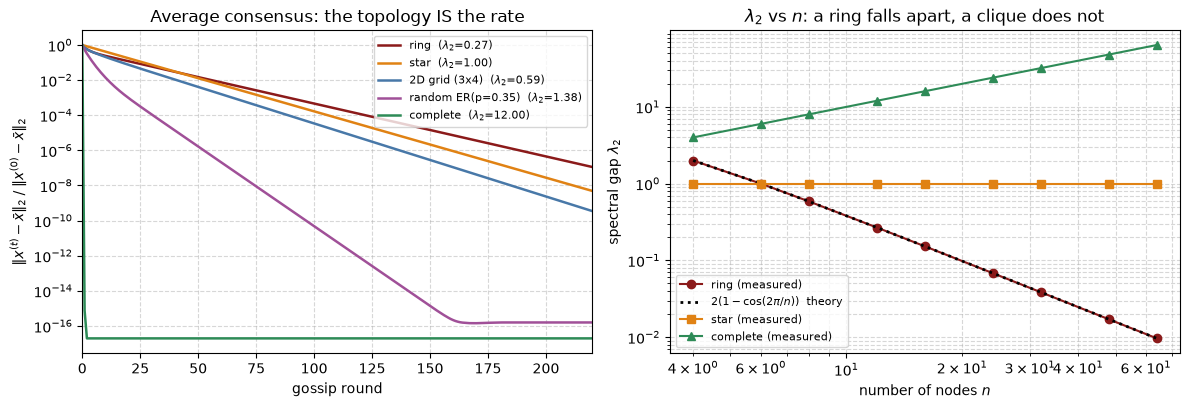

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

g_cols = {"ring": "#8b1a1a", "star": "#e08214", "2D grid (3x4)": "#4878a8",
          "random ER(p=0.35)": "#a05098", "complete": "#2e8b57"}
for name, errs in CONS.items():
    ax[0].semilogy(np.maximum(errs / errs[0], 1e-17), lw=1.8, color=g_cols[name],
                   label=f"{name}  ($\\lambda_2$={G_STATS[name]['lam2']:.2f})")
ax[0].set_xlabel("gossip round")
ax[0].set_ylabel(r"$\|x^{(t)} - \bar{x}\|_2 \; / \; \|x^{(0)} - \bar{x}\|_2$")
ax[0].set_title("Average consensus: the topology IS the rate")
ax[0].set_xlim(0, 220)
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5, which="both")

ns = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64])
lam2_ring = [np.sort(np.linalg.eigvalsh(laplacian(ring_graph(int(n)))))[1] for n in ns]
lam2_star = [np.sort(np.linalg.eigvalsh(laplacian(star_graph(int(n)))))[1] for n in ns]
lam2_comp = [np.sort(np.linalg.eigvalsh(laplacian(complete_graph(int(n)))))[1] for n in ns]
ax[1].loglog(ns, lam2_ring, "o-", color="#8b1a1a", label="ring (measured)")
ax[1].loglog(ns, 2 * (1 - np.cos(2 * np.pi / ns)), "k:", lw=2,
             label=r"$2(1-\cos(2\pi/n))$  theory")
ax[1].loglog(ns, lam2_star, "s-", color="#e08214", label="star (measured)")
ax[1].loglog(ns, lam2_comp, "^-", color="#2e8b57", label="complete (measured)")
ax[1].set_xlabel("number of nodes $n$")
ax[1].set_ylabel(r"spectral gap $\lambda_2$")
ax[1].set_title(r"$\lambda_2$ vs $n$: a ring falls apart, a clique does not")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

print(f"{'n':>5}  {'ring lambda_2':>14}  {'2(1-cos(2pi/n))':>16}  {'|difference|':>13}")
print("-" * 54)
for n_, l_ in zip(ns, lam2_ring):
    th = 2 * (1 - np.cos(2 * np.pi / n_))
    print(f"{n_:>5}  {l_:>14.6f}  {th:>16.6f}  {abs(l_ - th):>13.2e}")
print(f"\nThe ring's gap follows the closed form exactly, and it decays like O(1/n^2):")
print(f"   n=4 -> {lam2_ring[0]:.4f},  n=64 -> {lam2_ring[-1]:.6f}  "
      f"({lam2_ring[0] / lam2_ring[-1]:.0f}x smaller over a {ns[-1] // ns[0]}x change in n)")
print("Mixing time therefore grows like O(n^2). The complete graph's gap GROWS with n")
print("(lambda_2 = n), so it never degrades -- but every node needs n - 1 links.")

> **Observe:** the graph spectrum predicts how quickly clients agree.
>
> - **Complete graph:** one mixing step. Every client receives the exact average. This is the
>   mathematical averaging operation that AllReduce implements.
> - **Star:** only slightly faster than the ring—159 versus 189 rounds. Its larger $\lambda_2$
>   helps, but its large $\lambda_K$ makes our chosen step, $1/\lambda_K$, small. The ratio
>   $\lambda_2/\lambda_K$ explains the result.
> - **Ring:** increasingly slow as it grows. Information spreads through neighbours
>   gradually, and mixing takes roughly $O(n^2)$ rounds for a fixed error reduction.
> - **Random graph:** fast with far fewer links than the complete graph—53 rounds using 22
>   edges, versus 66.
>
> Ring gossip and ring AllReduce are different: gossip repeatedly averages neighbours and
> approaches the mean; AllReduce forwards information to compute the exact mean.
>
> **Connection to FedAvg:** decentralized training alternates local learning with neighbour
> averaging. FedAvg instead performs full, weighted averaging after local training. In
> decentralized training, clients must manage both local drift and incomplete mixing.


### 🔬 Exercise 4

**Exercise: the topology budget, and a metric that lies.** You are designing a decentralized
FL deployment with $n = 32$ clients. Each gossip round costs each client
$\deg(i)\cdot|\theta|$ bytes sent, so **denser graphs mix in fewer rounds but cost more per
round**. There should be an optimum in the middle. Go and find it.

1. For $n = 32$, build a **ring**, a **2D grid** ($4\times8$), a **random 4-regular graph**,
   and the **complete graph**. Report $\lambda_2$, $\lambda_2/\lambda_K$, and the gossip
   rounds to reach $10^{-6}$ consensus error.
2. Compute **total bytes per client** to reach that error: (rounds) × (degree) × $|\theta|$.
3. Which topology is cheapest by that metric? Is it the one with the largest $\lambda_2$?
   **Is the answer the one you expected?**
4. It is not. The metric in (2) says the *complete graph* wins — so either every
   decentralized FL system is wrong, or the metric is. Work out what "total bytes per
   client" is failing to charge for, and name at least two constraints a real deployment
   has that this number does not see.
5. Relate it to Week 5: a ring AllReduce moves $2\frac{P-1}{P}|\theta|$ per worker and gets
   the **exact** mean. Why does a ring *graph* need $O(n^2)$ rounds to get an approximate one?


In [33]:
# --- Reference solution (instructor: blank this out for students) ---

def random_regular(n, d, seed=0):
    # Pairing model with retries; fine for small n.
    r = np.random.default_rng(seed)
    for _ in range(2000):
        stubs = np.repeat(np.arange(n), d)
        r.shuffle(stubs)
        A = np.zeros((n, n))
        ok = True
        for i in range(0, len(stubs), 2):
            u, v = int(stubs[i]), int(stubs[i + 1])
            if u == v or A[u, v] > 0:
                ok = False; break
            A[u, v] = A[v, u] = 1.0
        if ok and np.sort(np.linalg.eigvalsh(laplacian(A)))[1] > 1e-8:
            return A
    raise RuntimeError("no regular graph found")


N32 = 32
BYTES_THETA = N_PARAMS * 4
cands = {"ring": ring_graph(N32), "2D grid (4x8)": grid_graph(4, 8),
         "random 4-regular": random_regular(N32, 4, seed=2), "complete": complete_graph(N32)}

x032 = np.random.default_rng(0).normal(size=N32) * 3.0
m032 = x032.mean()

print(f"n = {N32} clients, |theta| = {N_PARAMS:,} params = {BYTES_THETA:,} bytes")
print(f"{'graph':>18}  {'mean deg':>9}  {'max deg':>8}  {'lambda_2':>9}  {'gap ratio':>10}  "
      f"{'rounds':>7}  {'MB/client total':>16}")
print("-" * 88)
rows32 = []
for name, A in cands.items():
    L = laplacian(A)
    ev = np.sort(np.linalg.eigvalsh(L))
    lam2, lamK = ev[1], ev[-1]
    W = np.eye(N32) - L / lamK
    x, it = x032.copy(), 0
    e0 = np.linalg.norm(x - m032)
    while np.linalg.norm(x - m032) > 1e-6 * e0 and it < 200000:
        x = W @ x; it += 1
    deg = A.sum(1).mean()
    mb = it * deg * BYTES_THETA / 1e6
    rows32.append((name, deg, lam2, lam2 / lamK, it, mb))
    print(f"{name:>18}  {deg:>9.2f}  {int(A.sum(1).max()):>8}  {lam2:>9.4f}  "
          f"{lam2 / lamK:>10.4f}  {it:>7}  {mb:>16.2f}")

best = min(rows32, key=lambda r: r[5])
big_gap = max(rows32, key=lambda r: r[2])
print(f"\n(3) cheapest in BYTES : {best[0]}  ({best[5]:.2f} MB/client)")
print(f"    largest lambda_2  : {big_gap[0]}  ({big_gap[5]:.2f} MB/client)")
print(f"    same graph? {best[0] == big_gap[0]}")
print("\n    So the sparse-graph story this exercise set you up for is WRONG on this metric,")
print("    and we are not going to quietly rescale the axis until it is right. Mixing in ONE")
print("    round beats mixing in 1269, and it beats it by enough to pay for degree 31.")
print("    There is no interior optimum here. Denser is simply better, all the way up.")
print()
print("(4) So what is 'total bytes per client' failing to charge for? At least four things,")
print("    and each one is a constraint a real deployment actually has:")
print("    (a) DEGREE IS NOT FREE TO HAVE, only to use. The complete graph needs every")
print("        client to hold n-1 live connections to every other client. Cross-device")
print("        clients are behind NATs, on cellular, and intermittently online -- the")
print("        edges are not there to be used. The graph is a CONSTRAINT, not a choice.")
print("    (b) The metric is per-CLIENT, and Week 5's lesson is that the ceiling is at the")
print("        BUSIEST NODE. Here every node has degree 31 at once: 32 clients x 31")
print("        messages in a single round is an all-to-all burst, which is the parameter")
print("        server's 2P|g| spread across everyone rather than removed.")
print("    (c) DEGREE SCALES, and O(1)-degree is the whole point. Our n=32 is small. At")
print("        n=10^4 the complete graph needs 10^8 links; a 4-regular expander needs")
print("        2x10^4 and its spectral gap does NOT decay with n (unlike the ring's")
print("        O(1/n^2)). That is why real decentralized systems use EXPANDERS: gap that")
print("        stays O(1), degree that stays O(1).")
print("    (d) We priced EXACT consensus (1e-6). Decentralized SGD does not need it -- it")
print("        gossips once per local round and only needs rho small enough that the")
print("        1/(1-rho) factor in the bound is tolerable. Change the target from 1e-6 to")
print("        'one gossip step' and the per-round cost dominates: sparse graphs win.")
print("    The lesson is the transferable one: a cost model that omits a constraint will")
print("    confidently recommend violating it. Our model never knew the edges had to exist.")
print()
print("(5) Two different objects wearing the same word 'ring'.")
print("    Week 5's ring ALLREDUCE routes data ALL THE WAY AROUND: chunk k is forwarded")
print("    hop by hop, so after 2(P-1) steps every worker has seen a contribution from")
print("    every other. It computes the EXACT mean, and the ring is a schedule of messages.")
print("    Section 7's ring GRAPH only ever lets a node average with its 2 neighbours; it")
print("    never forwards, so information DIFFUSES like heat -- reaching the far side of")
print("    the ring takes O(n) rounds and equilibrating takes O(n^2). It computes an")
print("    APPROXIMATE mean, forever.")
print("    Routing beats diffusion. A server (or an AllReduce) is a routing schedule; gossip")
print("    is diffusion. That is what the server was buying you all along.")

n = 32 clients, |theta| = 914 params = 3,656 bytes
             graph   mean deg   max deg   lambda_2   gap ratio   rounds   MB/client total
----------------------------------------------------------------------------------------
              ring       2.00         2     0.0384      0.0096     1269              9.28
     2D grid (4x8)       3.25         4     0.1522      0.0210      515              6.12
  random 4-regular       4.00         4     0.8491      0.1188       95              1.39
          complete      31.00        31    32.0000      1.0000        1              0.11

(3) cheapest in BYTES : complete  (0.11 MB/client)
    largest lambda_2  : complete  (0.11 MB/client)
    same graph? True

    So the sparse-graph story this exercise set you up for is WRONG on this metric,
    and we are not going to quietly rescale the axis until it is right. Mixing in ONE
    round beats mixing in 1269, and it beats it by enough to pay for degree 31.
    There is no interior optimum he

---

## 8. Lab 7: FedAvg vs FedProx, IID vs non-IID

Lab 7 asks: **how much accuracy does label skew cost, and can FedProx recover it?**

Compare combinations of:

- **Data skew $\alpha$:** from nearly IID ($100$) to strongly non-IID ($0.1$).
- **Penalty $\mu$:** from $0$ (exactly FedAvg) to $1.0$.

Include **centralized SGD on pooled data** as a reference.

Use the faster `vmap` harness for this sweep. Section 4 verified that it matches Flower
aggregation within about $1.2\times10^{-7}$. Flower demonstrated the client/server lifecycle;
`vmap` produces the comparison results. State this clearly in your report.


In [34]:
# Reuse the Section 5 runs where we have them, fill in the rest.
LAB_ALPHAS = [100.0, 1.0, 0.3, 0.1]
LAB_MUS = [0.0, 0.01, 0.1, 1.0]

lab = {}
for a in LAB_ALPHAS:
    for mu in LAB_MUS:
        if (a, mu) in prox_runs:
            lab[(a, mu)] = prox_runs[(a, mu)]
        else:
            lab[(a, mu)] = run_fed(R_PROX, PARTS[a], mu=mu)
print(f"grid: {len(LAB_ALPHAS)} alphas x {len(LAB_MUS)} mus, {R_PROX} rounds each\n")

print(f"FINAL TEST ACCURACY after {R_PROX} rounds (tau={TAU}, K={K}, full participation)")
print(f"{'alpha':>8}  {'TV skew':>8}  " + "".join(f"{'mu=' + f'{m:g}':>10}" for m in LAB_MUS)
      + f"{'best mu':>9}  {'FedAvg vs IID':>14}")
print("-" * 88)
for a in LAB_ALPHAS:
    accs = [lab[(a, m)][-1]["acc"] for m in LAB_MUS]
    best = LAB_MUS[int(np.argmax(accs))]
    vs_iid = accs[0] - lab[(100.0, 0.0)][-1]["acc"]
    print(f"{a:>8.1f}  {skew_tv(PARTS[a]):>8.3f}  " + "".join(f"{x:>10.3f}" for x in accs)
          + f"{best:>9g}  {vs_iid:>+14.3f}")

print(f"\ncentralized SGD on the pooled data (same total gradient budget-ish): "
      f"acc {float(_a):.3f}, loss {float(_l):.4f}")
print(f"best federated cell in the grid: acc "
      f"{max(lab[(a, m)][-1]['acc'] for a in LAB_ALPHAS for m in LAB_MUS):.3f}")

wins = [(a, max(lab[(a, m)][-1]["acc"] for m in LAB_MUS[1:]) - lab[(a, 0.0)][-1]["acc"])
        for a in LAB_ALPHAS]
print(f"\nrows where SOME mu > 0 beat FedAvg (mu = 0): "
      f"{sum(1 for _, d in wins if d > 0)} of {len(LAB_ALPHAS)}")

# ...and now the number that decides whether that means anything. Before celebrating a
# +0.004 accuracy win, ask how big a win the MEASUREMENT can even resolve.
n_te = len(Y_te)
for a, d in wins:
    if d > 0:
        se = np.sqrt(0.9 * 0.1 / n_te)     # binomial s.e. of an accuracy near 0.9 on n_te
        print(f"   alpha={a:>5g}: best mu>0 beats FedAvg by {d:+.4f} "
              f"= {d * n_te:.0f} test examples out of {n_te}")
print(f"\n   For scale: the standard error of an accuracy near 0.9 on {n_te} test examples")
print(f"   is about {np.sqrt(0.9 * 0.1 / n_te):.4f}, i.e. +-{np.sqrt(0.9 * 0.1 / n_te) * n_te:.0f}")
print("   examples, before you even count run-to-run seed variance. Every 'win' above is")
print("   inside that: these differences are measurement noise, not evidence that FedProx")
print("   helps.")

grid: 4 alphas x 4 mus, 40 rounds each

FINAL TEST ACCURACY after 40 rounds (tau=16, K=6, full participation)
   alpha   TV skew        mu=0   mu=0.01    mu=0.1      mu=1  best mu   FedAvg vs IID
----------------------------------------------------------------------------------------
   100.0     0.036       0.978     0.976     0.958     0.652        0          +0.000
     1.0     0.379       0.975     0.976     0.967     0.670     0.01          -0.003
     0.3     0.523       0.947     0.946     0.944     0.724        0          -0.031
     0.1     0.619       0.845     0.849     0.823     0.453     0.01          -0.133

centralized SGD on the pooled data (same total gradient budget-ish): acc 0.980, loss 0.1123
best federated cell in the grid: acc 0.978

rows where SOME mu > 0 beat FedAvg (mu = 0): 2 of 4
   alpha=    1: best mu>0 beats FedAvg by +0.0010 = 1 test examples out of 1000
   alpha=  0.1: best mu>0 beats FedAvg by +0.0040 = 4 test examples out of 1000

   For scale: the sta

FedAvg accuracy, IID (a=100) : 0.978
centralized ceiling          : 0.980   (gap: +0.002 -- IID federation is nearly free)
FedAvg accuracy, a=0.1       : 0.845  (-0.133)
best FedProx at a=0.1        : 0.849


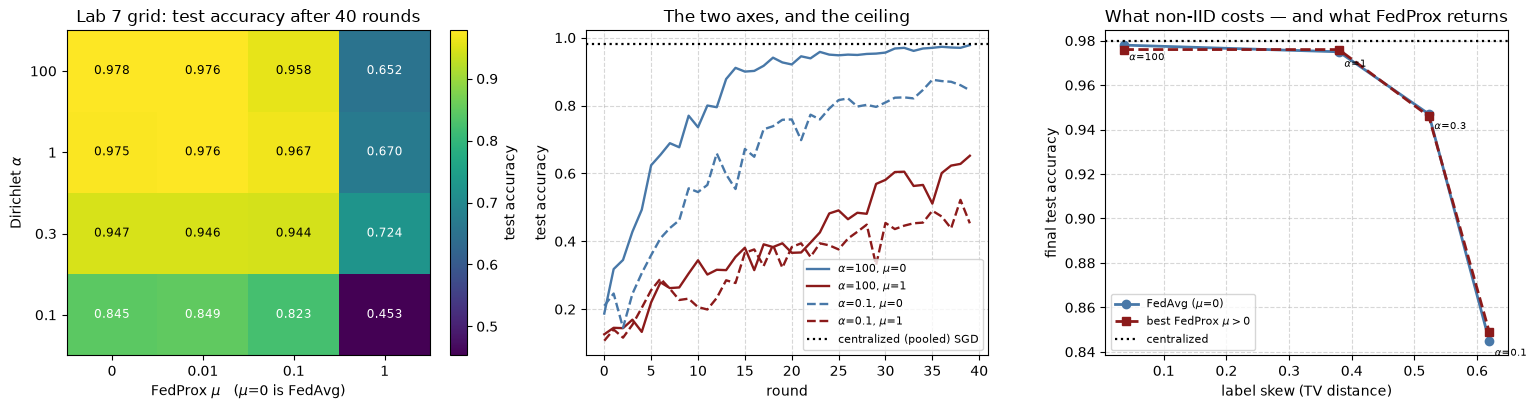

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.2))

# ---- 1: accuracy heat grid ----
G = np.array([[lab[(a, m)][-1]["acc"] for m in LAB_MUS] for a in LAB_ALPHAS])
im = ax[0].imshow(G, cmap="viridis", aspect="auto")
ax[0].set_xticks(range(len(LAB_MUS))); ax[0].set_xticklabels([f"{m:g}" for m in LAB_MUS])
ax[0].set_yticks(range(len(LAB_ALPHAS))); ax[0].set_yticklabels([f"{a:g}" for a in LAB_ALPHAS])
ax[0].set_xlabel(r"FedProx $\mu$   ($\mu$=0 is FedAvg)"); ax[0].set_ylabel(r"Dirichlet $\alpha$")
ax[0].set_title(f"Lab 7 grid: test accuracy after {R_PROX} rounds")
for i in range(len(LAB_ALPHAS)):
    for j in range(len(LAB_MUS)):
        ax[0].text(j, i, f"{G[i, j]:.3f}", ha="center", va="center", fontsize=8.5,
                   color="w" if G[i, j] < G.mean() else "k")
fig.colorbar(im, ax=ax[0], fraction=0.046, label="test accuracy")

# ---- 2: FedAvg vs FedProx curves, IID and non-IID ----
for a, ls in [(100.0, "-"), (0.1, "--")]:
    for mu, c in [(0.0, "#4878a8"), (1.0, "#8b1a1a")]:
        h = lab[(a, mu)]
        ax[1].plot([d["rnd"] for d in h], [d["acc"] for d in h], ls, color=c, lw=1.7,
                   label=f"$\\alpha$={a:g}, $\\mu$={mu:g}")
ax[1].axhline(float(_a), color="k", ls=":", lw=1.6, label="centralized (pooled) SGD")
ax[1].set_xlabel("round"); ax[1].set_ylabel("test accuracy")
ax[1].set_title("The two axes, and the ceiling")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5)

# ---- 3: the cost of non-IID, and whether mu recovers any of it ----
base_iid = lab[(100.0, 0.0)][-1]["acc"]
tv_x = [skew_tv(PARTS[a]) for a in LAB_ALPHAS]
ax[2].plot(tv_x, [lab[(a, 0.0)][-1]["acc"] for a in LAB_ALPHAS], "o-", color="#4878a8",
           lw=2, label=r"FedAvg ($\mu$=0)")
ax[2].plot(tv_x, [max(lab[(a, m)][-1]["acc"] for m in LAB_MUS[1:]) for a in LAB_ALPHAS],
           "s--", color="#8b1a1a", lw=2, label=r"best FedProx $\mu > 0$")
ax[2].axhline(float(_a), color="k", ls=":", lw=1.6, label="centralized")
ax[2].set_xlabel("label skew (TV distance)"); ax[2].set_ylabel("final test accuracy")
ax[2].set_title("What non-IID costs — and what FedProx returns")
ax[2].legend(fontsize=8); ax[2].grid(True, ls="--", alpha=0.5)
for a, x_ in zip(LAB_ALPHAS, tv_x):
    ax[2].annotate(f"$\\alpha$={a:g}", (x_, lab[(a, 0.0)][-1]["acc"]), fontsize=7.5,
                   textcoords="offset points", xytext=(4, -11))

plt.tight_layout()

print(f"FedAvg accuracy, IID (a=100) : {lab[(100.0, 0.0)][-1]['acc']:.3f}")
print(f"centralized ceiling          : {float(_a):.3f}   "
      f"(gap: {float(_a) - lab[(100.0, 0.0)][-1]['acc']:+.3f} -- IID federation is nearly free)")
print(f"FedAvg accuracy, a=0.1       : {lab[(0.1, 0.0)][-1]['acc']:.3f}  "
      f"({lab[(0.1, 0.0)][-1]['acc'] - base_iid:+.3f})")
print(f"best FedProx at a=0.1        : {max(lab[(0.1, m)][-1]['acc'] for m in LAB_MUS[1:]):.3f}")

### One global number is not the whole story: who is it good *for*?

Every accuracy in the grid above is measured on a **balanced global test set** — the
distribution you get by pooling. That is the right metric for the objective FedAvg claims to
optimize ($F = \sum_k p_k F_k$), and it is the wrong metric for the question a deployed system
is judged on: *does this model work for **each** client?*

Under non-IID data those come apart, because the global model is a compromise and a
compromise is not equally good news for everyone. So measure the global model's accuracy on
**each client's own label distribution**, and report the **worst** one. That number —
worst-client accuracy — is Week 11's motivation (if the compromise fails a client badly
enough, give it its *own* model) and a theme of Week 14 (a mean can hide who is failed).


In [36]:
Y_te_np = np.asarray(Y_te)

def per_client_accuracy(params, bn, shards, n_eval=400, seed=0):
    # The global model, scored on HELD-OUT test examples drawn with each client's own label
    # mix. (Scoring on the client's training examples would be in-sample.)
    r = np.random.default_rng(seed)
    out = []
    for s in shards:
        q = np.bincount(Yh[s], minlength=N_CLASSES) / max(len(s), 1)
        labels = r.choice(N_CLASSES, size=n_eval, p=q)
        idx = np.array([r.choice(np.where(Y_te_np == c)[0]) for c in labels])
        _, a = evaluate(params, bn, X_te[idx], Y_te[idx])
        out.append(float(a))
    return np.array(out)


# Re-run FedAvg to the end and keep the final model (run_fed only returns history).
def final_model(rounds, shards, mu=0.0):
    Kk = len(shards)
    sizes = np.array([len(s) for s in shards], dtype=np.float64)
    w = jnp.asarray(sizes / sizes.sum(), dtype=jnp.float32)
    sp, sb, so = params0, bn0, opt0
    for r in range(rounds):
        xs, ys = sample_batches(shards, TAU, r)
        cp, cb, co, _ = run_clients(broadcast(sp, Kk), broadcast(sb, Kk), broadcast(so, Kk),
                                    xs, ys, mu)
        sp, sb, so = aggregate(cp, w), aggregate(cb, w), aggregate(co, w)
    return sp, sb


print(f"the GLOBAL FedAvg model, scored on each client's label mix ({R_PROX} rounds, mu=0;")
print("held-out test examples, 400 per client)")
print(f"{'partition':>16}  " + "".join(f"{'c' + str(k):>7}" for k in range(K)) +
      f"{'global':>9}{'worst':>8}{'spread':>8}")
print("-" * 78)
worst_rows = []
for a in [100.0, 0.3, 0.1]:
    sp_f, sb_f = final_model(R_PROX, PARTS[a])
    pc = per_client_accuracy(sp_f, sb_f, PARTS[a])
    g = lab[(a, 0.0)][-1]["acc"]
    worst_rows.append((a, pc, g))
    print(f"{'alpha = ' + f'{a:g}':>16}  " + "".join(f"{v:>7.3f}" for v in pc) +
          f"{g:>9.3f}{pc.min():>8.3f}{pc.max() - pc.min():>8.3f}")

print()
print("Read the last two columns, not the 'global' one.")
print(f"  IID (a=100): worst client {worst_rows[0][1].min():.3f} vs global "
      f"{worst_rows[0][2]:.3f} -- the spread is {worst_rows[0][1].max() - worst_rows[0][1].min():.3f}.")
print(f"               With IID clients every client IS the global distribution, so 'good on")
print(f"               average' and 'good for everyone' are the same sentence.")
print(f"  a=0.1      : worst client {worst_rows[-1][1].min():.3f}, spread "
      f"{worst_rows[-1][1].max() - worst_rows[-1][1].min():.3f} -- they have come apart.")
print()
print("How to read this: a client's score is the global model's accuracy on the classes")
print("that client holds, weighted by its label mix. A low score means the shared model is")
print("weak on exactly the classes that client cares about. With 400 test examples per")
print("client the standard error is about 0.015 near 90% accuracy, so gaps of a few points")
print("are noise; the alpha = 0.1 spread is far larger than that. The narrow claim: as alpha")
print("falls, the global number stops describing individual clients.")

the GLOBAL FedAvg model, scored on each client's label mix (40 rounds, mu=0;
held-out test examples, 400 per client)
       partition       c0     c1     c2     c3     c4     c5   global   worst  spread
------------------------------------------------------------------------------


     alpha = 100    0.975  0.987  0.975  0.962  0.982  0.967    0.978   0.962   0.025


     alpha = 0.3    0.880  0.895  0.845  0.915  0.787  0.912    0.947   0.787   0.127


     alpha = 0.1    0.370  0.710  0.335  0.780  0.962  0.782    0.845   0.335   0.627

Read the last two columns, not the 'global' one.
  IID (a=100): worst client 0.962 vs global 0.978 -- the spread is 0.025.
               With IID clients every client IS the global distribution, so 'good on
               average' and 'good for everyone' are the same sentence.
  a=0.1      : worst client 0.335, spread 0.627 -- they have come apart.

How to read this: a client's score is the global model's accuracy on the classes
that client holds, weighted by its label mix. A low score means the shared model is
weak on exactly the classes that client cares about. With 400 test examples per
client the standard error is about 0.015 near 90% accuracy, so gaps of a few points
are noise; the alpha = 0.1 spread is far larger than that. The narrow claim: as alpha
falls, the global number stops describing individual clients.


> **Observe — the Lab 7 result.**
>
> 1. **IID federation is nearly free here.** FedAvg at $\alpha = 100$ reaches $0.978$ test
>    accuracy, close to centralized SGD's $0.980$ with the same gradient budget, while
>    communicating only once every $\tau = 16$ steps. So federating, local steps, and
>    averaging are not what cost accuracy in this experiment.
> 2. **Non-IID data costs accuracy, and the cost grows as $\alpha$ falls**: $0.978 \to 0.975
>    \to 0.947 \to 0.845$ for $\alpha = 100, 1, 0.3, 0.1$. The ordering matches the drift
>    measured in Section 3. Part of the effect may come from size imbalance, which the
>    Dirichlet partition changes at the same time (Exercise 1).
> 3. **FedProx does not help in this grid.** In every row the best $\mu$ is $0$, or a
>    $\mu > 0$ that wins by at most 4 test examples out of 1000 — well within noise. Section 5
>    lists the likely reasons: a short round budget, no systems heterogeneity, and a small
>    problem.
> 4. **The remaining gap is the main result.** At $\alpha = 0.1$ FedAvg stays about 13 points
>    below the IID run, and nothing in this grid closes that gap. On the quadratic, SCAFFOLD
>    removes the drift bias at $2\times$ communication and with stateful clients; we did not
>    test it on the CNN (Further Exercise 3).
> 5. **The global number hides who is failed.** At $\alpha = 0.1$ the global accuracy is
>    $0.845$, but on some clients' label mixes the same model scores far lower.
>
> **How to write this up.** A null result on 6 clients, ~900 parameters, and synthetic data
> does not show that FedProx never works; it shows that this experiment could not detect a
> benefit. Say which claim you are making. The GPU-node version of Lab 7 (100 clients, real
> CIFAR-10) is where to test it at scale.


---

## Summary

Week 9 took apart the first of Week 7's four constraints: **non-IID data**.

- **Client drift is bias, not just noise.** On a noiseless quadratic, FedAvg converges to the
  solution of $\sum_k p_k M_k (w - w_k) = 0$ with $M_k = I - (I - \eta H_k)^\tau$, not to
  $\theta^\star$; the closed form matched the experiment to $10^{-15}$. At $\tau = 1$ the two
  coincide. As $\tau$ grows, curvature information is lost and the fixed point moves toward
  the average of the client optima. More rounds do not remove this bias; a smaller learning
  rate reduces it but slows each round.
- **Dirichlet($\alpha$) controls the skew.** It changes label mix and client size together
  (Exercise 1 separates them). Large $\alpha$ is slightly *more* uniform than a random split;
  small $\alpha$ sends each class to one client, but a client can still hold several classes
  — or none.
- **Measure drift with more than one instrument.** Spread, update cosine, and normalized
  update variance all worsen as $\alpha$ falls; the variance moves most. Drift is nonzero
  even under IID data, so compare levels rather than asking whether drift exists.
- **Stage 4 was a port.** `local_block` ran unchanged in real Flower client processes and
  matched the `vmap` harness to float32 precision. The model is built from Equinox library
  classes because a notebook-defined `eqx.Module` loses its PyTree registration in a Ray
  worker.
- **FedProx is a brake.** $\mu = 0$ recovers FedAvg exactly. Larger $\mu$ shortens local
  moves, but plain SGD on the penalized loss diverges once $\eta(L + \mu) \geq 2$, so $\mu$
  and $\eta$ must be tuned together. On the CNN no $\mu > 0$ beat FedAvg beyond noise. On the
  quadratic, FedProx shrinks the bias but leaves a nonzero floor.
- **SCAFFOLD corrects the direction.** With control variates every client follows the
  global gradient; on the quadratic the bias is $\approx 10^{-16}$ at every $\tau$. The costs
  are $2\times$ communication in both directions and client memory. Stale control variates
  slowed convergence but did not break exactness here; clients without memory lose the
  correction entirely.
- **Consensus replaces the server with a graph.** The Laplacian measures disagreement, and
  the achievable mixing rate is $1 - \lambda_2/\lambda_K$, not $\lambda_2$ alone. A complete
  graph mixes in one step (an AllReduce); on a ring, mixing time grows like $O(n^2)$.
- **Lab 7.** IID FedAvg nearly matches centralized SGD at the same gradient budget. Accuracy
  falls as $\alpha$ falls ($0.978 \to 0.845$ from $\alpha = 100$ to $0.1$), and FedProx did
  not close that gap here.

**Next.** Week 10 reduces communication: the client update $\Delta_k$ is what gets
compressed, and SCAFFOLD's $2\times$ lands on the scarcest link. Week 11 gives up on a single
global model (personalization, FedBN, graph-based FL). Weeks 12–13 ask what the transmitted
arrays reveal, and what happens when a client lies.

### Further Exercises

1. **Find the asymptote, and test the transient.** Section 8 reports a 40-round budget, and
   Section 5 blames FedProx's failure on not being drift-limited yet. Both claims are about
   what happens *later*. Run $\alpha \in \{100, 1, 0.3, 0.1\}$ at $\mu \in \{0, 0.1\}$ for
   400 rounds and plot accuracy vs round. (a) Does each curve flatten, and does the
   flattening height track Section 3's update variance — i.e. is the plateau the biased fixed
   point Section 1 predicts? (b) Does $\mu > 0$ overtake $\mu = 0$ once the plateau is
   reached, as Section 5 predicted it should? If it does not, Section 5's excuse was wrong
   and you should say so. (c) Watch the mild-skew rows early: after 12 rounds in Section 3,
   $\alpha = 1$ was briefly *ahead* of IID. Does that lead persist? Explain why an early lead
   is not a result.
2. **Give FedProx its actual case.** Section 5 argues FedProx is built for $\tau_k$
   heterogeneity, which we switched off. Switch it on: draw $\tau_k \sim
   \text{Uniform}\{2,\dots,32\}$ per client per round (Week 7's `local_block` masked
   variable trip counts with a `live` argument; port it), and sweep $\mu$ at $\alpha = 0.1$.
   Report against a matched-compute control (Week 7's lesson: heterogeneity changes the
   compute, so an unmatched comparison measures the wrong thing). Does $\mu > 0$ win now?
3. **SCAFFOLD on the real model.** We only ran SCAFFOLD on the quadratic, deliberately —
   convex is where the claim is unambiguous. Port it to the CNN: add $c_k$ to the client
   state (a PyTree the same shape as `params`), thread it through `local_block`, and
   implement the Option-II refresh. Compare against FedAvg at $\alpha = 0.1$ on **accuracy
   vs bytes**, not accuracy vs rounds — SCAFFOLD moves 2× per round, so an accuracy-vs-round
   plot is a rigged comparison.
4. **FedNova and FedAdam, composed.** Week 7's $\Delta$ form showed the server is just an
   optimizer on a pseudo-gradient with $\eta_s = 1$. Swap `optax.sgd(1.0)` for
   `optax.adam(...)` at the server (FedAdam; Reddi et al., 2021) and combine it with FedNova's
   $\tau_k$ normalization. Do server-side momentum and client-side drift correction compose,
   or do they fight?
5. **Decentralized FedAvg.** Replace the server with the mixing matrix of Section 7: each
   client does $\tau$ local steps, then $\theta \leftarrow W\theta$ across the graph. Sweep
   the topology (ring / grid / random 4-regular / complete) at $\alpha = 0.1$ and plot
   accuracy against **total bytes sent per client**. Check whether the convergence gap grows
   with $\frac{1}{1 - \rho(W)}$, as the theory suggests. Where does the server earn its keep?
6. **Break the $M_k$ story.** Section 1's bias came from clients having different
   **curvature**, not different **optima**. Construct three quadratics with identical $H_k$
   but different $w_k$, and predict — before running — what FedAvg's bias will be at
   $\tau = 50$. Then run it. What does the answer say about which kind of non-IID actually
   hurts, and how would you detect that kind in a real deployment where you cannot see the
   clients' data?
